# How detections are scored

The evaluation protocol behind this project's CFAR-vs-deep-learning comparison, end to end: how a
detector's score map becomes a list of detections, which cells are eligible to be judged, how those
detections are matched to ground truth, and how the resulting counts become Pd, Pfa and localization
error — with the uncertainty and the limitations attached.

**This is the ruler, not the measurement.** There is no CFAR-vs-DL result here. Worked examples use
either clearly-labelled toy detections or the `bench2_val` split, so nothing in this notebook is a
second read of the reported split; the few `bench2_test` numbers quoted are read from cached
artefacts produced by the pre-registered run.

**Why it matters that this is written down.** Both detector families are reduced to the *same*
output type — a list of `(range_bin, velocity_bin, score)` points — and scored by the *same* code.
A comparison is only as fair as the rules both sides are held to, so the rules are stated here in
full, including the ones that are conventions rather than laws.

Run top to bottom. Nothing here modifies data or results.

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch
from scipy.ndimage import maximum_filter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

# The project's own evaluation code. Every rule this notebook describes is executed from here,
# never re-implemented below.
from cfar.cfar import CfarConfig, cfar_ratio_map
from cfar.detect import all_peaks, extract_detections, _collapse_plateaus
from dl.infer import cfar_valid_mask, predict_heatmap
from dl.models import TinyCNN
from eval import MatchConfig, aggregate, evaluate_frame
from eval.detection import _guard_mask
from radar.config import RadarConfig, derive_radar_params
import torch

CFG = RadarConfig()
DERIVED = derive_radar_params(CFG)
CFAR_CFG = CfarConfig()

SHAPE = (CFG.N // 2, CFG.M)          # the RD map the detectors see
NMS = 5                              # the shared NMS radius (src/dl/infer.py NMS_SIZE)
TARGET_PFA = 1e-4
N_BOOT = 2000                        # bootstrap resamples, project-wide
GATE = MatchConfig(1, 1)             # the pre-registered headline gate
GATE3 = MatchConfig(3, 3)            # the robustness gate

RES_R, RES_V = DERIVED.range_res, DERIVED.vel_res
DLR = ROOT / "results" / "dl"

# One scenario order everywhere, matching dataset_overview.ipynb.
ORDER = ["isolated", "masking", "unresolved", "clutter", "clutter_edge", "multi", "mixed"]

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9"
BLUE, ORANGE, AQUA, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#8172b3"
RED, GREY = "#d1495b", "#b8b6ae"
METHOD_COLOR = {"CA": BLUE, "GO": AQUA, "OS": PURPLE, "SO": "#c9a227", "DL": ORANGE}

plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": "#c3c2b7", "grid.color": GRID,
                     "text.color": INK, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED,
                     "font.size": 10, "figure.dpi": 110})


def tidy(ax):
    ax.grid(axis="y", linewidth=0.8)
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)


def fmt_p(p, n_boot=2000):
    """Bootstrap p-values have a resolution floor. Never print p = 0."""
    floor = 2.0 / n_boot                      # the statistic is two-sided: 2 * min(tail, tail)
    return f"< {floor:.3f}" if p < floor else f"{p:.3f}"


# Cached ground truth for bench2_val, shared by sections 3.1a, 4.1 and 10. Reading a cached
# detection file is not a read of a split -- no frame data is opened here.
CV = ROOT / "results" / "cfar_val"
FM_VAL = pd.read_csv(CV / "frames.csv")
TB = {f: g[["range_bin", "velocity_bin"]].to_numpy(float)
      for f, g in pd.read_csv(CV / "truths.csv").groupby("frame")}


def load_peaks(path):
    a = np.load(path)["peaks"]
    return {int(f): a[a[:, 0] == f][:, 1:] for f in np.unique(a[:, 0])}


print(f"RD map {SHAPE[0]} x {SHAPE[1]}   bin = {RES_R:.3f} m x {RES_V:.3f} m/s")
print(f"CFAR window {2 * CFAR_CFG.half_width_r + 1} x {2 * CFAR_CFG.half_width_d + 1}"
      f"   NMS radius {NMS}   headline gate +/-{GATE.tol_r} bin")

RD map 256 x 64   bin = 0.195 m x 0.420 m/s
CFAR window 21 x 9   NMS radius 5   headline gate +/-1 bin


---
## 0 · Evaluation at a glance

Both detector families end in the same place: a 2D score map over the Range–Doppler grid. Everything
after that point is shared code, so the two arms cannot diverge in post-processing.

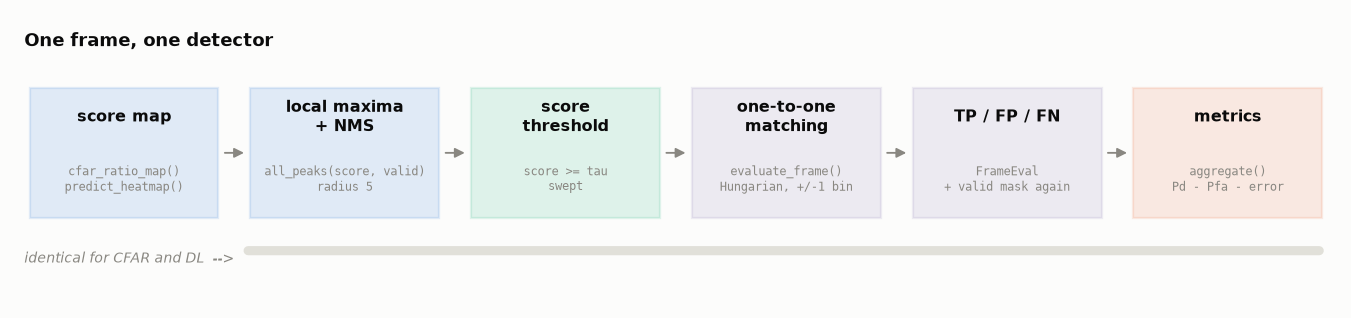

In [2]:
fig, ax = plt.subplots(figsize=(15.6, 3.5))
ax.set_xlim(0, 100); ax.set_ylim(0, 10); ax.axis("off")

stages = [
    ("score map", "cfar_ratio_map()\npredict_heatmap()", BLUE),
    ("local maxima\n+ NMS", "all_peaks(score, valid)\nradius 5", BLUE),
    ("score\nthreshold", "score >= tau\nswept", AQUA),
    ("one-to-one\nmatching", "evaluate_frame()\nHungarian, +/-1 bin", PURPLE),
    ("TP / FP / FN", "FrameEval\n+ valid mask again", PURPLE),
    ("metrics", "aggregate()\nPd - Pfa - error", ORANGE),
]
w, gap = 14.2, 2.4
for i, (title, fn, c) in enumerate(stages):
    x = 1.4 + i * (w + gap)
    ax.add_patch(Rectangle((x, 3.0), w, 4.4, facecolor=c, alpha=0.13,
                           edgecolor=c, linewidth=1.5))
    ax.text(x + w / 2, 6.4, title, ha="center", va="center", fontsize=10.5, weight="bold")
    ax.text(x + w / 2, 4.3, fn, ha="center", va="center", fontsize=8, color=MUTED,
            family="monospace")
    if i < len(stages) - 1:
        ax.add_patch(FancyArrowPatch((x + w + 0.25, 5.2), (x + w + gap - 0.25, 5.2),
                                     arrowstyle="-|>", mutation_scale=13,
                                     color=MUTED, linewidth=1.2))

ax.text(1.0, 1.5, "identical for CFAR and DL  -->", fontsize=9, color=MUTED, style="italic")
ax.annotate("", xy=(98.6, 1.9), xytext=(17.6, 1.9),
            arrowprops=dict(arrowstyle="-", color=GRID, linewidth=6))
ax.text(1.0, 8.8, "One frame, one detector", fontsize=12, weight="bold")
plt.show()

*<span style='color:#6b6b6b'>Note the order: NMS runs on the raw score map and the score cut comes after it, so the candidate set is fixed once and the ROC sweep only moves the cut. Section 1.1a explains why, and appendix A.1 checks the result against thresholding inside peak extraction.</span>*

### The choices that define the comparison

| choice | value | where it is justified |
|---|---|---|
| post-processing | one `all_peaks()`, NMS radius 5, for both arms | §1 |
| evaluation region | the CFAR-testable interior, same mask for both arms | §2 |
| matching | optimal one-to-one, Hungarian assignment | §3 |
| headline gate | **±1 bin**, pre-registered | §3 |
| robustness gate | ±3 bin, reported beside it | §3 |
| operating point | matched **measured** post-NMS Pfa = 1e-4, per condition | §5, §7 |
| uncertainty | paired frame bootstrap, 2,000 resamples | §8 |
| multiplicity | Bonferroni over the 7 scored conditions, α = 0.0071 | §9 |

Two of these are worth flagging immediately as *conventions*, not facts: the guard-region exclusion
in §4, and the per-condition threshold in §7. Both are defensible, both change what the numbers
mean, and both are stated rather than buried.

---
## 1 · From a score map to detections

**The question:** a detector assigns a score to every one of the 16,384 cells. How does that become
a short list of "there is a target here"?

In [3]:
# One real frame, from bench2_val. Both detectors are run on it.
FRAME_DIR = next(fd for fd in sorted((ROOT / "data" / "bench2_val" / "frames").iterdir())
                 if json.loads((fd / "metadata.json").read_text())["condition"] == "masking")
MAG = np.load(FRAME_DIR / "rd_map_mag.npy")
LAB = pd.read_csv(FRAME_DIR / "labels.csv")
TRUTHS = LAB[["range_bin", "velocity_bin"]].to_numpy(float)

VALID = cfar_valid_mask(SHAPE, CFAR_CFG)
RATIO, CFAR_VALID, _ = cfar_ratio_map(MAG ** 2, CFAR_CFG)

_ck = torch.load(ROOT / "results" / "dl" / "tinycnn_frozen_s0_ep021.pt", weights_only=False)
MODEL = TinyCNN(width=_ck["config"].get("width", 16))
MODEL.load_state_dict(_ck["state_dict"])
MODEL.eval()
LOGIT = predict_heatmap(MODEL, MAG)          # logits, not probabilities -- see §1.2

print(f"frame {FRAME_DIR.name}  condition=masking  {len(LAB)} targets")
print(f"CFAR ratio map : {RATIO.shape}, range {RATIO.min():.2f} to {RATIO.max():.2f} (power ratio)")
print(f"DL score map   : {LOGIT.shape}, range {LOGIT.min():.2f} to {LOGIT.max():.2f} (logits)")

frame frame_000001  condition=masking  2 targets
CFAR ratio map : (256, 64), range 0.00 to 70.90 (power ratio)
DL score map   : (256, 64), range -13.22 to 9.22 (logits)


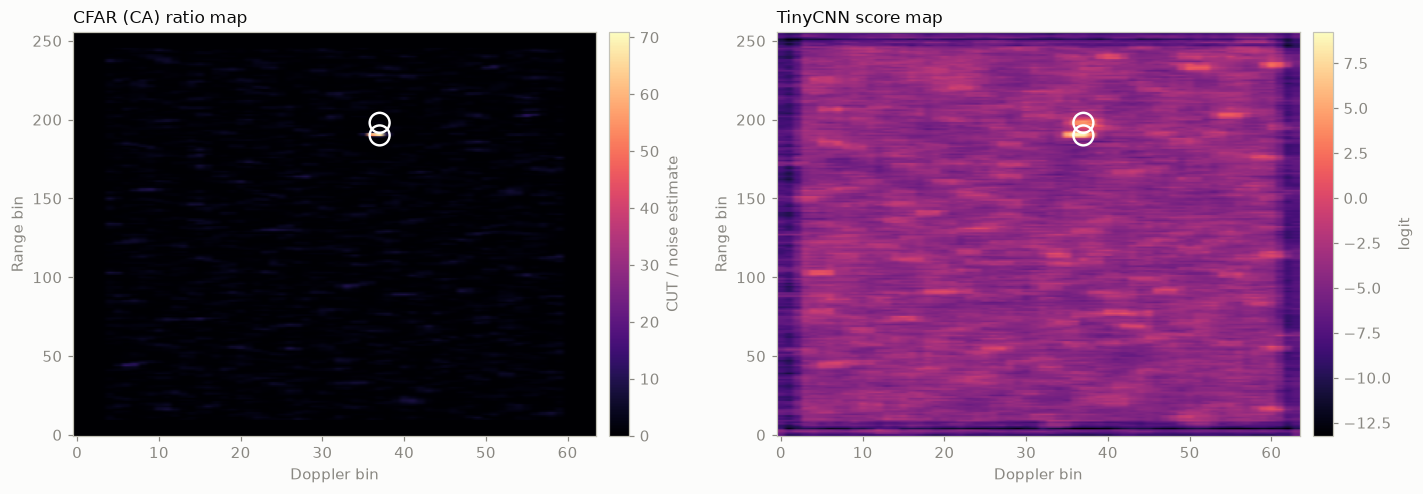

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.6))
for ax, (M, name, unit) in zip(axes, [(RATIO, "CFAR (CA) ratio map", "CUT / noise estimate"),
                                      (LOGIT, "TinyCNN score map", "logit")]):
    im = ax.imshow(M, aspect="auto", origin="lower", cmap="magma")
    ax.scatter(TRUTHS[:, 1], TRUTHS[:, 0], s=170, facecolors="none",
               edgecolors="white", linewidths=1.6)
    ax.set_title(name, loc="left", fontsize=11)
    ax.set_xlabel("Doppler bin"); ax.set_ylabel("Range bin")
    ax.grid(False)
    fig.colorbar(im, ax=ax, label=unit, pad=0.02)
plt.tight_layout(); plt.show()

*<span style='color:#6b6b6b'>Two different statistics on two different scales — but structurally the same object, a score per cell. White rings are the two labelled targets. Everything downstream treats these maps identically.</span>*

### 1.1 The four stages, in the order the code applies them

**The question:** which cells survive, and why?

Note the ordering, because it is easy to get backwards. **NMS runs first, on the raw score map,
before the operating threshold.** The score cut comes afterwards. Both arms are cut at the operating
point they are really scored at — the matched *measured* Pfa threshold for that condition — so the
two rows below differ only in the score map they start from.

In [5]:
COND_DEMO = "masking"
OPP = pd.read_csv(DLR / "roc_operating_points_val_tol1.csv")


def matched_cut(method, cond=COND_DEMO):
    """The threshold at which this method is actually scored on this condition (section 7)."""
    return float(OPP[(OPP.condition == cond) & (OPP.method == method)].threshold.iloc[0])


THR_CA, THR_DL = matched_cut("CA"), matched_cut("DL")

# For contrast only: the DESIGN threshold CFAR theory derives, which is NOT where anything is
# scored. The gap between the two is the point section 4.2 of cfar_baseline.ipynb makes.
design = pd.DataFrame([
    dict(variant=k, design_alpha=CfarConfig(kind=k).resolved_alpha(), matched=matched_cut(k))
    for k in ("CA", "GO", "OS", "SO")]).set_index("variant")
design["matched / design"] = design.matched / design.design_alpha
display(design.round(4))
print(f"Every variant is scored below its design alpha, by nearly the same factor "
      f"({design['matched / design'].min():.3f}-{design['matched / design'].max():.3f}).")
print("That common offset is the post-NMS-vs-per-cell effect of section 5.1, not miscalibration:")
print("alpha is a per-cell threshold, while these cuts are matched on post-NMS detections.")
print()
print(f"cuts used below:  CA {THR_CA:.3f} (power ratio)   DL {THR_DL:.3f} (logits)")

,design_alpha,matched,matched / design
variant,,,
CA,10.4586,9.9681,0.9531
GO,9.5458,9.2017,0.9640
OS,7.5786,7.2059,0.9508
SO,12.8494,12.2812,0.9558


Every variant is scored below its design alpha, by nearly the same factor (0.951-0.964).
That common offset is the post-NMS-vs-per-cell effect of section 5.1, not miscalibration:
alpha is a per-cell threshold, while these cuts are matched on post-NMS detections.

cuts used below:  CA 9.968 (power ratio)   DL 1.392 (logits)


In [6]:
def stages(score, thr):
    """Stage 2 (NMS, before the cut) then stage 3 (the cut) -- the real order."""
    pts = all_peaks(score, VALID, nms_size=NMS)       # every local max above the score>0 floor
    keep = pts[:, 2] >= thr if len(pts) else np.zeros(0, dtype=bool)

    # The same primitives all_peaks() composes, kept to show the peak test and to size the floor.
    peak = score == maximum_filter(score, size=2 * NMS + 1, mode="nearest")
    survivors = _collapse_plateaus(VALID & peak & (score > 0))
    assert ({(int(r), int(c)) for r, c in np.argwhere(survivors)} ==
            {(int(q[0]), int(q[1])) for q in pts}), "stage 2 must reproduce all_peaks() exactly"

    # Diagnostic only, NOT a pipeline stage: local maxima before the score>0 floor.
    no_floor = int(_collapse_plateaus(VALID & peak).sum())

    return pts, keep, no_floor


CF_PTS, CF_KEEP, CF_RAW = stages(RATIO, THR_CA)
DL_PTS, DL_KEEP, DL_RAW = stages(LOGIT, THR_DL)

summary = pd.DataFrame([
    dict(arm="CFAR (CA)", local_maxima=CF_RAW, candidates=len(CF_PTS),
         removed_by_floor=CF_RAW - len(CF_PTS), detections=int(CF_KEEP.sum()),
         cells_over_cut=int(((RATIO > THR_CA) & VALID).sum())),
    dict(arm="TinyCNN", local_maxima=DL_RAW, candidates=len(DL_PTS),
         removed_by_floor=DL_RAW - len(DL_PTS), detections=int(DL_KEEP.sum()),
         cells_over_cut=int(((LOGIT > THR_DL) & VALID).sum())),
]).set_index("arm")
display(summary)
print("`candidates` is stage 2: computed once, reused at every threshold the ROC sweeps.")
print("`cells_over_cut` is NOT a pipeline stage; it sizes what NMS removes.")
cpd = summary.cells_over_cut / summary.detections.clip(lower=1)
print(f"The two arms reach the same detection count from different score-map shapes. Above the")
print(f"cut, CFAR has {cpd['CFAR (CA)']:.1f} cells per detection and the network {cpd['TinyCNN']:.1f}:")
print("CFAR's above-threshold cells are already nearly isolated, while the network responds with")
print("a blob that NMS has to collapse. `removed_by_floor` is explained in 1.1b.")

,local_maxima,candidates,removed_by_floor,detections,cells_over_cut
arm,,,,,
CFAR (CA),115,115,0,3,7
TinyCNN,80,13,67,3,31


`candidates` is stage 2: computed once, reused at every threshold the ROC sweeps.
`cells_over_cut` is NOT a pipeline stage; it sizes what NMS removes.
The two arms reach the same detection count from different score-map shapes. Above the
cut, CFAR has 2.3 cells per detection and the network 10.3:
CFAR's above-threshold cells are already nearly isolated, while the network responds with
a blob that NMS has to collapse. `removed_by_floor` is explained in 1.1b.


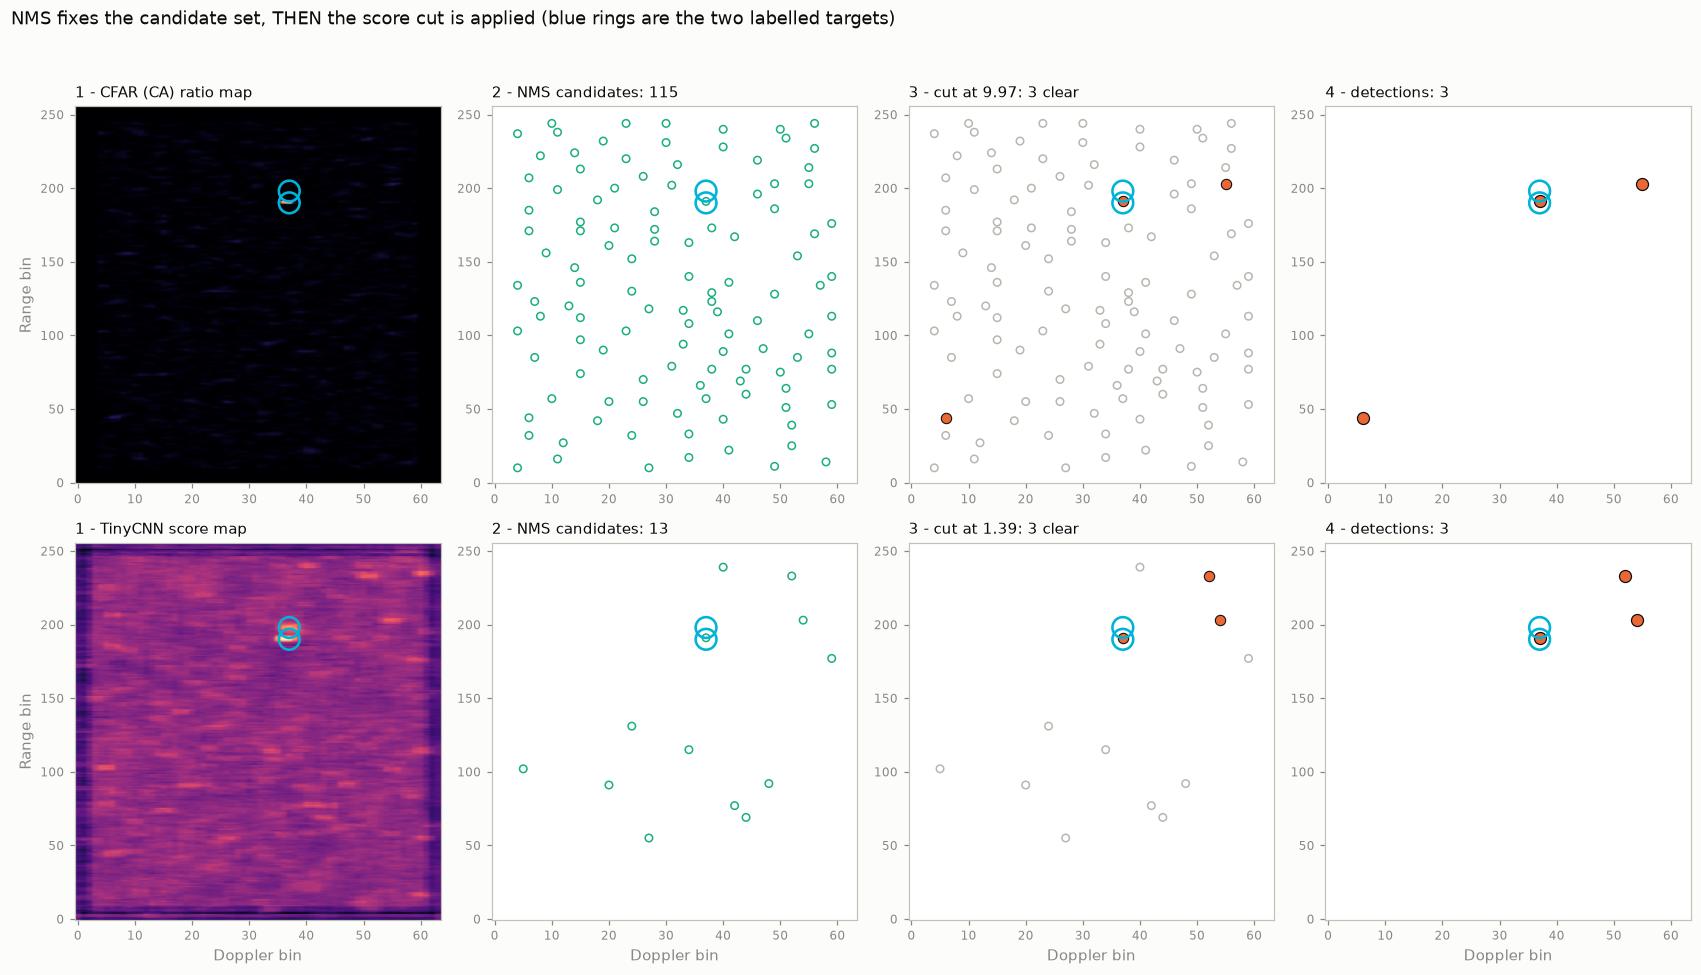

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(15.5, 9.0))
rows = [("CFAR (CA) ratio map", RATIO, CF_PTS, CF_KEEP, THR_CA),
        ("TinyCNN score map", LOGIT, DL_PTS, DL_KEEP, THR_DL)]

for row, (name, score, pts, keep, thr) in zip(axes, rows):
    row[0].imshow(score, aspect="auto", origin="lower", cmap="magma")
    row[0].set_title(f"1 - {name}", loc="left", fontsize=9.5)

    row[1].scatter(pts[:, 1], pts[:, 0], s=24, facecolor="none", edgecolor=AQUA, linewidths=1.0)
    row[1].set_title(f"2 - NMS candidates: {len(pts)}", loc="left", fontsize=9.5)

    row[2].scatter(pts[~keep, 1], pts[~keep, 0], s=24, facecolor="none", edgecolor=GREY,
                   linewidths=1.0)
    row[2].scatter(pts[keep, 1], pts[keep, 0], s=46, color=ORANGE, edgecolor=INK, linewidths=0.7)
    row[2].set_title(f"3 - cut at {thr:.2f}: {int(keep.sum())} clear", loc="left", fontsize=9.5)

    row[3].scatter(pts[keep, 1], pts[keep, 0], s=62, color=ORANGE, edgecolor=INK, linewidths=0.8)
    row[3].set_title(f"4 - detections: {int(keep.sum())}", loc="left", fontsize=9.5)

    for k, ax in enumerate(row):
        if k:                                  # stages 2-4: plain white, markers only
            ax.set_facecolor("white")
        ax.scatter(TRUTHS[:, 1], TRUTHS[:, 0], s=185, facecolors="none",
                   edgecolors="#00b4d8", linewidths=1.7, zorder=6)
        ax.set_xlim(-0.5, SHAPE[1] - 0.5)
        ax.set_ylim(-0.5, SHAPE[0] - 0.5)
        ax.grid(False)
        ax.tick_params(labelsize=8)
    row[0].set_ylabel("Range bin")

for ax in axes[-1]:
    ax.set_xlabel("Doppler bin")
fig.suptitle("NMS fixes the candidate set, THEN the score cut is applied "
             "(blue rings are the two labelled targets)", x=0.005, ha="left", fontsize=11.5)
plt.tight_layout(rect=(0, 0, 1, 0.955))
plt.show()

*<span style='color:#6b6b6b'>Stages 2-4 are drawn on plain white so only the markers carry information, and both rows are built identically. Panel 2 is the whole candidate set and is the same at every threshold; panel 3 is the only thing the ROC sweep moves, re-colouring candidates as the cut rises or falls. Both arms find the strong target of the pair; the weak one is missing from panel 2 onwards, and the cell below says why.</span>*

**Where did the weak target go?** The pair is 8 range bins apart, so the weak target's absence
is *not* caused by the radius-5 NMS interaction between the two — 8 bins is outside that reach. It is
tempting to conclude it was therefore rejected by the score cut, but that has to be checked rather
than assumed: a target that never formed a local maximum never reaches the cut at all.

In [8]:
rows = []
for arm, pts, thr in (("CFAR (CA)", CF_PTS, THR_CA), ("TinyCNN", DL_PTS, THR_DL)):
    for name, (tr, tv) in zip(("strong", "weak"), TRUTHS):
        near = pts[(np.abs(pts[:, 0] - tr) <= NMS) & (np.abs(pts[:, 1] - tv) <= NMS)]
        rows.append(dict(arm=arm, target=name, bin=f"({int(tr)},{int(tv)})",
                         candidates_within_5_bins=len(near),
                         best_score=round(float(near[:, 2].max()), 3) if len(near) else np.nan,
                         clears_cut=bool((near[:, 2] >= thr).any()) if len(near) else False))
display(pd.DataFrame(rows).style.hide(axis="index"))
print("Neither arm produced a candidate peak anywhere near the weak target, so it was not")
print("rejected by the score cut -- it never became a local maximum in the first place. The")
print("strong target 8 bins away cannot suppress it at radius 5, so this is neither the")
print("pairwise NMS interaction nor the cut: the weak return simply never peaked.")

arm,target,bin,candidates_within_5_bins,best_score,clears_cut
CFAR (CA),strong,"(190,37)",1,70.897000,True
CFAR (CA),weak,"(198,37)",0,nan,False
TinyCNN,strong,"(190,37)",1,9.223000,True
TinyCNN,weak,"(198,37)",0,nan,False


Neither arm produced a candidate peak anywhere near the weak target, so it was not
rejected by the score cut -- it never became a local maximum in the first place. The
strong target 8 bins away cannot suppress it at radius 5, so this is neither the
pairwise NMS interaction nor the cut: the weak return simply never peaked.


### 1.1a Why NMS comes first — and what the NMS footprint costs

These are two separate things, and it is worth keeping them apart.

**Why NMS comes first: the reason is computational.** Candidate peaks are extracted once so the ROC
can sweep many score thresholds without re-running the 11 × 11 maximum filter each time. For this
max-filter implementation, applying the score threshold before or after NMS gives the same final
detections over the reported operating range — appendix **A.1** checks it on real frames. The
ordering is therefore a matter of cost, **not a methodological choice**, and it changes no result.

A second, smaller benefit: the candidate set cannot shift underneath the sweep, so every point on
the curve describes the same peaks judged more or less strictly.

**What the NMS footprint costs: the reason is geometric.** Radius 5 means an **11 × 11 suppression
neighbourhood**. Two genuinely resolvable targets whose peaks fall inside that neighbourhood
suppress one another — only the stronger survives as a candidate, and no threshold can recover the
other. The reach is ±5 bins: **0.98 m in range, 2.10 m/s in Doppler**.

**This limitation is independent of whether thresholding happens before or after NMS.** It follows
from the size of the window, not from the order of operations, and it is the mechanism behind the
`masking` ceiling already recorded in the limitations (on clean maps only ~38% of masking pairs keep
both targets, and 5.9% of pairs closer than 1 m).

The synthetic pair below isolates exactly that geometry.

In [9]:
# Synthetic, not a measurement: two peaks on an empty map, both far above any threshold used.
# Isolates the NMS footprint by removing every other effect -- no noise, no clutter, no cut.
demo = []
for sep in (3, 5, 6, 8):
    m = np.zeros((40, 40))
    m[20, 20], m[20 + sep, 20] = 50.0, 30.0          # strong peak, weaker neighbour
    pk = all_peaks(m, np.ones_like(m, dtype=bool), nms_size=NMS)
    demo.append(dict(separation_bins=sep, separation_m=sep * RES_R,
                     candidates=len(pk),
                     detections_at_cut_10=int((pk[:, 2] >= 10).sum())))
display(pd.DataFrame(demo).set_index("separation_bins").round(3))
print("Both peaks (50 and 30) are far above the cut of 10, so the cut removes nothing here and")
print("threshold ordering is irrelevant -- the only variable is separation.")
print(f"Within {NMS} bins the weaker peak never becomes a candidate; from {NMS + 1} bins both do.")
print("That is the NMS footprint acting alone, which is what makes it evidence about geometry")
print("rather than about thresholding.")

,separation_m,candidates,detections_at_cut_10
separation_bins,,,
3,0.586,1,1
5,0.976,1,1
6,1.171,2,2
8,1.561,2,2


Both peaks (50 and 30) are far above the cut of 10, so the cut removes nothing here and
threshold ordering is irrelevant -- the only variable is separation.
Within 5 bins the weaker peak never becomes a candidate; from 6 bins both do.
That is the NMS footprint acting alone, which is what makes it evidence about geometry
rather than about thresholding.


### 1.1b "Candidate" means *before the operating cut*, not unfiltered

`all_peaks()` keeps local maxima with **`score > 0`**. That floor is not the operating threshold, but
it is not nothing either, and it lands very differently on the two arms — which is what the
`removed_by_floor` column above is showing.

* **CFAR: inert.** The ratio is CUT power over a noise estimate, positive by construction, so
  nothing is removed.
* **The network: dominant.** Scored on logits, `score > 0` means sigmoid > 0.5, and most local
  maxima on a real frame sit below that. It removes the large majority of them.

**No reported number is affected**, because everything the floor removes is at or below 0 while the
operating cut sits well above it — those peaks would have failed the cut anyway. But it does mean
the network's candidate count is *not* "every local maximum", and a DL ROC cannot be swept past that
point toward higher Pfa. Quantified in appendix **A.2**.

### 1.2 Three details that are easy to get wrong

**`nms_size = 5` is a radius, not a window size.** `all_peaks` passes `size = 2 * nms_size + 1` to
`maximum_filter`, so the suppression window is **11 × 11 cells** — every peak must be the maximum of
the 121 cells around it. Physically that is a wide window, which is a documented trade: it caps the
`masking` scenario near Pd 0.69 because it merges genuinely resolvable pairs, and shrinking it is
measurably worse because NMS also filters noise (the reasoning is in `src/cfar/detect.py`).

In [10]:
rows = [
    ("nms_size (radius, per side)", f"{NMS} bins"),
    ("suppression window", f"{2 * NMS + 1} x {2 * NMS + 1} cells"),
    ("window span, range", f"{(2 * NMS + 1) * RES_R:.2f} m"),
    ("window span, Doppler", f"{(2 * NMS + 1) * RES_V:.2f} m/s"),
    ("measured mainlobe half-width", "2 bins (-30 dB, set by the Blackman window)"),
]
display(pd.DataFrame(rows, columns=["", "value"]).style.hide(axis="index"))

,value
"nms_size (radius, per side)",5 bins
suppression window,11 x 11 cells
"window span, range",2.15 m
"window span, Doppler",4.62 m/s
measured mainlobe half-width,"2 bins (-30 dB, set by the Blackman window)"


**Both arms call the same function object.** Not "the same algorithm" — the same function. This
is checked rather than asserted in prose:

In [11]:
import cfar.detect as _cd, dl.infer as _di
print("dl.infer.all_peaks is cfar.detect.all_peaks :", _di.all_peaks is _cd.all_peaks)
print("DL NMS radius (src/dl/infer.py)            :", _di.NMS_SIZE)
print("CFAR NMS radius used here                  :", NMS)

print()
print(f"candidate peaks from that one call: "
      f"{len(all_peaks(RATIO, VALID, nms_size=NMS))} on the CFAR map, "
      f"{len(all_peaks(LOGIT, VALID, nms_size=NMS))} on the DL map")

dl.infer.all_peaks is cfar.detect.all_peaks : True
DL NMS radius (src/dl/infer.py)            : 5
CFAR NMS radius used here                  : 5

candidate peaks from that one call: 115 on the CFAR map, 13 on the DL map


**Plateau collapse exists because of the network, and applies to both.** `score ==
maximum_filter(score)` marks *every* cell of a flat region as a local maximum. A CFAR ratio is
continuous and rarely ties; a network's output has genuinely flat regions, so without
`_collapse_plateaus` one target could emit several detections — which, sitting inside a truth's
guard region (§4), would cost nothing in false alarms while inflating detections. Collapsing to one
representative per connected region removes the asymmetry, and is applied to both arms.

**The DL map is scored as logits, not probabilities.** The sigmoid is monotone, so no metric
changes — but in float32 it saturates to exactly 1.0 above a logit of about 9.7, which would tie
hundreds of cells and destroy resolution at exactly the low-Pfa end where the operating point sits.
One consequence of the shared `all_peaks` is worth knowing: it keeps cells with `score > 0`, so on
the DL arm only positive logits ever become candidate peaks. The appendix checks that the operating
point sits well above that floor, so it binds on nothing reported.

---
## 2 · Which cells are eligible to be judged

**The question:** CFAR needs a full reference window around a cell to estimate noise there. Cells
near the border do not have one. What happens to them?

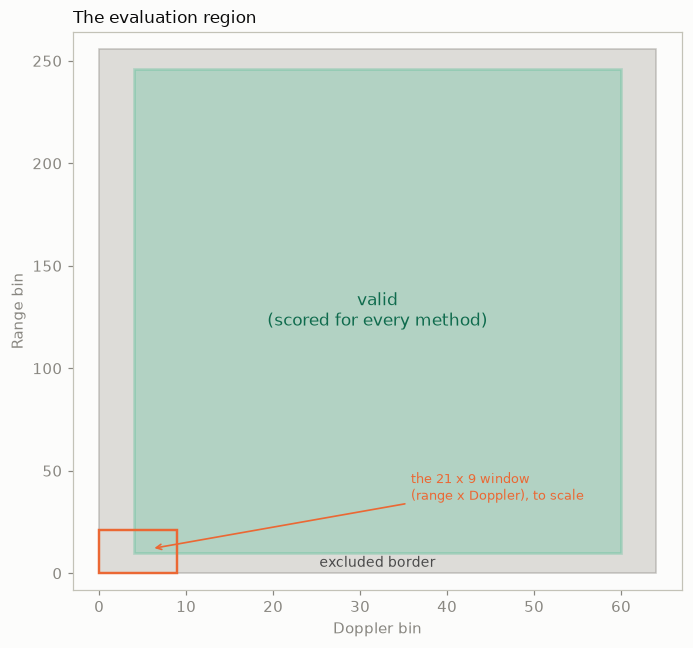

,value
full RD map,"256 x 64 = 16,384 cells"
CFAR window,21 range x 9 Doppler
excluded margin,"10 bins in range, 4 in Doppler, each side"
valid region,"236 x 56 = 13,216 cells"
fraction of the map,80.7%


In [12]:
hw_r, hw_d = CFAR_CFG.half_width_r, CFAR_CFG.half_width_d

fig, ax = plt.subplots(figsize=(6.4, 6.0))
ax.add_patch(Rectangle((0, 0), SHAPE[1], SHAPE[0], facecolor=GREY, alpha=0.45,
                       edgecolor=MUTED, linewidth=1.0))
ax.add_patch(Rectangle((hw_d, hw_r), SHAPE[1] - 2 * hw_d, SHAPE[0] - 2 * hw_r,
                       facecolor=AQUA, alpha=0.22, edgecolor=AQUA, linewidth=1.8))
# The CFAR window, drawn to scale at a cell just inside the valid region.
ax.add_patch(Rectangle((hw_d - CFAR_CFG.half_width_d, hw_r - CFAR_CFG.half_width_r),
                       2 * hw_d + 1, 2 * hw_r + 1, facecolor="none",
                       edgecolor=ORANGE, linewidth=1.6))
ax.text(SHAPE[1] / 2, SHAPE[0] / 2, "valid\n(scored for every method)", ha="center", va="center",
        fontsize=11, color="#0f6b4d")
ax.text(SHAPE[1] / 2, hw_r / 2, "excluded border", ha="center", va="center", fontsize=9,
        color="#4a4a4a")
ax.annotate(f"the {2 * hw_r + 1} x {2 * hw_d + 1} window\n(range x Doppler), to scale",
            xy=(hw_d + 2, hw_r + 2), xytext=(SHAPE[1] * 0.56, SHAPE[0] * 0.14),
            fontsize=8.5, color=ORANGE,
            arrowprops=dict(arrowstyle="->", color=ORANGE, linewidth=1.1))
ax.set_xlim(-3, SHAPE[1] + 3); ax.set_ylim(-8, SHAPE[0] + 8)
ax.set_xlabel("Doppler bin"); ax.set_ylabel("Range bin")
ax.set_title("The evaluation region", loc="left", fontsize=11)
ax.grid(False)
plt.tight_layout(); plt.show()

rows = [
    ("full RD map", f"{SHAPE[0]} x {SHAPE[1]} = {SHAPE[0] * SHAPE[1]:,} cells"),
    ("CFAR window", f"{2 * hw_r + 1} range x {2 * hw_d + 1} Doppler"),
    ("excluded margin", f"{hw_r} bins in range, {hw_d} in Doppler, each side"),
    ("valid region", f"{SHAPE[0] - 2 * hw_r} x {SHAPE[1] - 2 * hw_d} = {int(VALID.sum()):,} cells"),
    ("fraction of the map", f"{100 * VALID.mean():.1f}%"),
]
display(pd.DataFrame(rows, columns=["", "value"]).style.hide(axis="index"))

*<span style='color:#6b6b6b'>The border is excluded, not padded — padding would invent reference cells and bias the noise estimate. The margin is rectangular because the window is: 21 bins in range, 9 in Doppler.</span>*

**The same mask is applied to the network, which does not need it.** A CNN produces a score
everywhere, border included. Scoring it on cells CFAR cannot test would give it targets to find and
— more importantly — a larger false-alarm denominator, so identical behaviour would show a lower
Pfa. Sharing the mask keeps the denominator identical on both sides.

The dataset is built so this costs nothing: `verify_splits.py` confirms **zero targets** fall in the
excluded border, so no method is denied a detection it could have made.

---
## 3 · Matching detections to ground truth

**The question:** a detection lands one bin from a target. Is that a hit?

**The rule.** A detection is *eligible* for a truth when it lies inside the tolerance gate —
`|Δrange| ≤ tol` **and** `|Δdoppler| ≤ tol`, a square gate, not a circle. Among eligible pairs the
assignment is **optimal and one-to-one**: `scipy.optimize.linear_sum_assignment` over a cost matrix
of in-gate Euclidean distances, with out-of-gate pairs made unaffordable.

Three properties follow, and all three are checked in §3.2:

* one detection cannot claim two truths,
* one truth cannot yield two TPs,
* the chosen pairing minimises total localization distance among valid pairings.

In [13]:
# A toy frame. These are INVENTED detections on a small grid, chosen to exercise every outcome;
# they are not measurements. The scoring is done by the project's own evaluate_frame().
TOY_SHAPE = (18, 18)
TOY_TRUTHS = np.array([[4.0, 4.0],      # A - clean hit
                       [4.0, 12.0],     # B - hit, plus a second detection nearby
                       [12.0, 4.0],     # C - detection just outside the gate
                       [12.0, 12.0]])   # D - nothing near it
TOY_DETS = np.array([[5.0, 4.0],        # -> A, offset (+1, 0)
                     [4.0, 12.0],       # -> B, exact
                     [3.0, 11.0],       # near B, but B is taken: forgiven, inside B's guard
                     [14.0, 6.0],       # near C but 2 bins away: outside the gate
                     [9.0, 16.0]])      # nowhere near anything
TOY_LABELS = ["A", "B", "C", "D"]

ev1 = evaluate_frame(TOY_DETS, TOY_TRUTHS, TOY_SHAPE, GATE)
print(f"gate +/-1 :  TP={ev1.tp}  FP={ev1.fp}  FN={ev1.fn}   matched truths={ev1.matched_truth_idx}")
print(f"            localization errors  dr={ev1.dr}  dv={ev1.dv}")

gate +/-1 :  TP=2  FP=2  FN=2   matched truths=[0, 1]
            localization errors  dr=[1, 0]  dv=[0, 0]


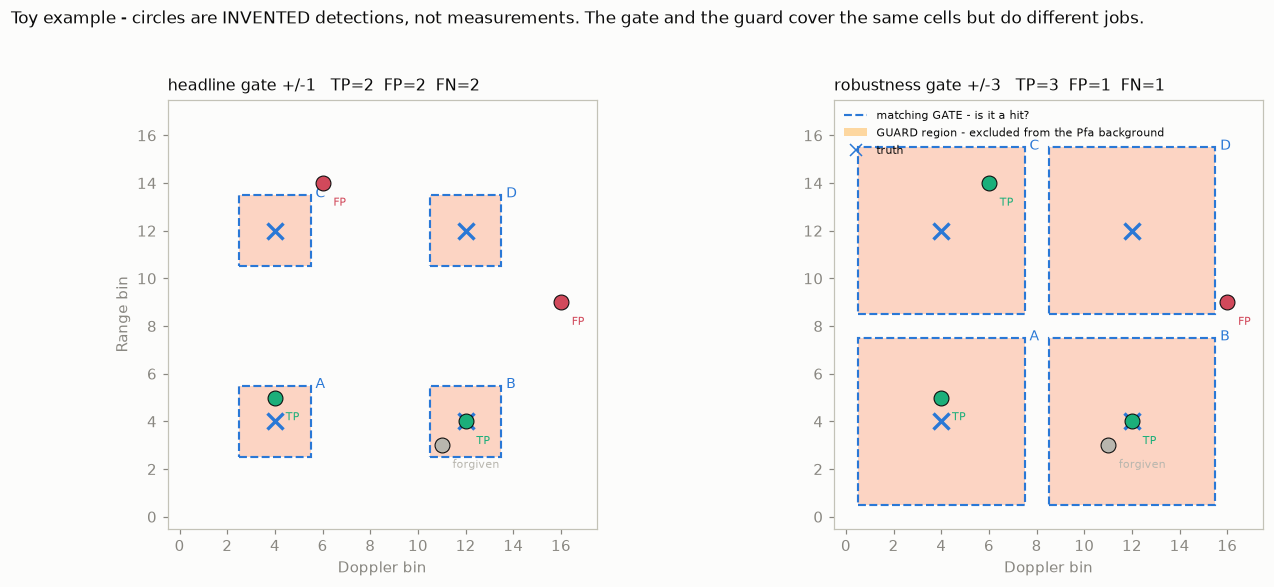

In [14]:
def draw_toy(ax, cfg, title):
    """One toy frame at one tolerance. The GATE and the GUARD are drawn separately."""
    guard = _guard_mask(TOY_TRUTHS, TOY_SHAPE, cfg)
    ev = evaluate_frame(TOY_DETS, TOY_TRUTHS, TOY_SHAPE, cfg)

    # GUARD (amber fill): cells excluded from the false-alarm background.
    ax.imshow(np.ma.masked_where(~guard, guard.astype(float)), origin="lower",
              cmap="autumn_r", alpha=0.22, vmin=0, vmax=1.4)

    for (r, v), name in zip(TOY_TRUTHS, TOY_LABELS):
        # GATE (blue dashed outline): which detection counts as a hit.
        ax.add_patch(Rectangle((v - cfg.tol_v - 0.5, r - cfg.tol_r - 0.5),
                               2 * cfg.tol_v + 1, 2 * cfg.tol_r + 1,
                               facecolor="none", edgecolor=BLUE, linewidth=1.4, linestyle="--"))
        ax.scatter(v, r, marker="x", s=110, color=BLUE, linewidths=2.2, zorder=4)
        ax.text(v + cfg.tol_v + 0.7, r + cfg.tol_r + 0.4, name, fontsize=9, color=BLUE)

    matched_det = set()
    d = np.asarray(TOY_DETS, float)
    for j, k in enumerate(ev.matched_truth_idx):
        t = TOY_TRUTHS[k]
        hit = np.flatnonzero((d[:, 0] == t[0] + ev.dr[j]) & (d[:, 1] == t[1] + ev.dv[j]))
        matched_det.add(int(hit[0]))

    for i, (r, v) in enumerate(d):
        in_guard = bool(guard[int(r), int(v)])
        if i in matched_det:
            c, lab = AQUA, "TP"
        elif in_guard:
            c, lab = GREY, "forgiven"
        else:
            c, lab = RED, "FP"
        ax.scatter(v, r, marker="o", s=95, facecolor=c, edgecolor=INK, linewidths=0.7, zorder=5)
        ax.text(v + 0.45, r - 0.95, lab, fontsize=7.5, color=c, zorder=6)

    ax.set_title(f"{title}   TP={ev.tp}  FP={ev.fp}  FN={ev.fn}", loc="left", fontsize=10.5)
    ax.set_xlim(-0.5, TOY_SHAPE[1] - 0.5)
    ax.set_ylim(-0.5, TOY_SHAPE[0] - 0.5)
    ax.set_xlabel("Doppler bin")
    ax.grid(False)
    return ev


fig, axes = plt.subplots(1, 2, figsize=(12.6, 5.4))
EV1 = draw_toy(axes[0], GATE, "headline gate +/-1")
EV3 = draw_toy(axes[1], GATE3, "robustness gate +/-3")
axes[0].set_ylabel("Range bin")

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
axes[1].legend(handles=[
    Line2D([0], [0], color=BLUE, ls="--", lw=1.4, label="matching GATE - is it a hit?"),
    Patch(facecolor="#ffb347", alpha=0.5, label="GUARD region - excluded from the Pfa background"),
    Line2D([0], [0], marker="x", color=BLUE, lw=0, markersize=8, label="truth"),
], loc="upper left", fontsize=7.5, frameon=False)

fig.suptitle("Toy example - circles are INVENTED detections, not measurements. "
             "The gate and the guard cover the same cells but do different jobs.",
             x=0.005, ha="left", fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

*<span style='color:#6b6b6b'>A and B are hits; the second detection near B is *forgiven* rather than counted against the detector (§4); the detection 2 bins from C is a miss AND a false alarm at ±1; D is a plain miss. The right panel is the same frame judged more leniently — the table below counts exactly what changes, rather than asking you to take a number on trust.</span>*

### 3.1 Why ±1 is the headline and ±3 is only a check

The headline tolerance is **±1 bin in each axis, forming a 3 × 3 gate** — nine cells, not one. The
two axes are deliberately given the same *bin* tolerance even though a range bin and a Doppler bin
are different physical quantities (0.195 m against 0.420 m/s); the gate is defined in bins because
that is the grid the detectors and the labels live on, and the physical asymmetry is a consequence
to be aware of rather than a mistake.

±1 was **pre-registered** as the headline before the test split was read. ±3 is reported beside it
because a rule that is too tight can flatter a detector that detects well but localises badly.
Widening the gate can only turn misses into hits, never the reverse, so Pd is monotone in the
gate.

In [15]:
widen = pd.DataFrame(
    [dict(gate="+/-1", TP=EV1.tp, FP=EV1.fp, FN=EV1.fn,
          gate_cells=(2 * GATE.tol_r + 1) * (2 * GATE.tol_v + 1),
          guard_cells=int(_guard_mask(TOY_TRUTHS, TOY_SHAPE, GATE).sum()),
          cells_tested=EV1.cells_tested),
     dict(gate="+/-3", TP=EV3.tp, FP=EV3.fp, FN=EV3.fn,
          gate_cells=(2 * GATE3.tol_r + 1) * (2 * GATE3.tol_v + 1),
          guard_cells=int(_guard_mask(TOY_TRUTHS, TOY_SHAPE, GATE3).sum()),
          cells_tested=EV3.cells_tested)]
).set_index("gate")
display(widen)

d_tp, d_fp = EV3.tp - EV1.tp, EV1.fp - EV3.fp
print(f"Widening to +/-3 converts {d_tp} miss{'' if d_tp == 1 else 'es'} into "
      f"{d_tp} hit{'' if d_tp == 1 else 's'}, and reclassifies {d_fp} false "
      f"alarm{'' if d_fp == 1 else 's'} as forgiven.")
print(f"The gate grows from {widen.gate_cells.iloc[0]} cells to {widen.gate_cells.iloc[1]} "
      f"({widen.gate_cells.iloc[1] / widen.gate_cells.iloc[0]:.1f}x the area) --")
print(f"and the guard grows with it, from {widen.guard_cells.iloc[0]} to "
      f"{widen.guard_cells.iloc[1]} cells. That is the subject of 3.1a.")

,TP,FP,FN,gate_cells,guard_cells,cells_tested
gate,,,,,,
+/-1,2,2,2,9,36,288
+/-3,3,1,1,49,196,128


Widening to +/-3 converts 1 miss into 1 hit, and reclassifies 1 false alarm as forgiven.
The gate grows from 9 cells to 49 (5.4x the area) --
and the guard grows with it, from 36 to 196 cells. That is the subject of 3.1a.


### 3.1a The gate and the guard are different things — and they are *coupled*

They cover the same cells, but they do opposite jobs:

| | question it answers | effect |
|---|---|---|
| **matching gate** | is this detection close enough to count as a **hit**? | sets TP and FN |
| **guard region** | is this *unmatched* detection a **near-target detection** to be set aside, or a false alarm? | sets FP, and removes those cells from the Pfa **denominator** |

**They are not independent.** `evaluate_frame` builds the guard from the *same* `MatchConfig` that
defines the gate, so **widening the gate widens the guard too**, and the false-alarm denominator
shrinks with it. That is visible in the toy table above and it is measurable on real data:

In [16]:
rows = []
for cond in ("isolated", "multi"):
    ids = FM_VAL.loc[FM_VAL.condition == cond, "frame"].to_numpy()
    cells = {}
    for tol, cfg in ((1, GATE), (3, GATE3)):
        cells[tol] = sum(
            evaluate_frame(np.zeros((0, 2)), TB.get(i, np.zeros((0, 2))), SHAPE, cfg,
                           valid_mask=VALID).cells_tested for i in ids)
    rows.append(dict(condition=cond, frames=len(ids),
                     cells_tested_gate1=cells[1], cells_tested_gate3=cells[3],
                     change=cells[3] / cells[1] - 1))
G = pd.DataFrame(rows).set_index("condition")
display(G.style.format({"cells_tested_gate1": "{:,}", "cells_tested_gate3": "{:,}",
                        "change": "{:+.2%}"}))
print("The denominator shrinks because more cells sit inside some truth's (wider) guard.")
print("The effect scales with target density -- `multi` has 4-5 targets per frame, `isolated` 1.")

,frames,cells_tested_gate1,cells_tested_gate3,change
condition,,,,
isolated,200,"2,641,400","2,633,400",-0.30%
multi,200,"2,635,118","2,599,203",-1.36%


The denominator shrinks because more cells sit inside some truth's (wider) guard.
The effect scales with target density -- `multi` has 4-5 targets per frame, `isolated` 1.


**Why this does not invalidate the matched-Pfa comparison — and what it does mean.**

Each gate is a **self-contained analysis**. Within one gate, the denominator depends only on the
truths, the valid mask and the tolerance — never on the detector — so both arms are measured against
*identical* denominators and the matched operating point is genuinely matched. Nothing about the
comparison at ±1 is affected by what ±3 would have done.

What it does mean is that **±1 and ±3 are two different operating points**, not one result viewed
two ways: the threshold that achieves a measured Pfa of 1e-4 differs slightly between them, because
the rate is computed over a slightly different background. So the ±3 row is a *re-run of the whole
protocol* at a looser tolerance, which is exactly what makes it a robustness check. What you must
never do is read a Pd from one gate against a Pfa from the other.

**In practice the guard convention is doing almost nothing**, and §4.1 measures exactly how little
at the matched operating point across every condition and method — the count is computed there
rather than quoted here. NMS and plateau collapse remove the duplicate responses the guard rule
exists to set aside, so it is a safety net that catches essentially nothing. That measurement is the
strongest form of the argument that the convention is not quietly doing work in the results.

### 3.2 The three matching properties, executed

In [17]:
# (a) one detection between two truths cannot satisfy both
two_truths = np.array([[5.0, 5.0], [5.0, 7.0]])
one_det = np.array([[5.0, 6.0]])
a = evaluate_frame(one_det, two_truths, TOY_SHAPE, GATE)

# (b) two detections on one truth yield one TP
one_truth = np.array([[5.0, 5.0]])
two_dets = np.array([[5.0, 5.0], [5.0, 6.0]])
b = evaluate_frame(two_dets, one_truth, TOY_SHAPE, GATE)

# (c) the assignment minimises total in-gate distance: brute-force every valid pairing.
from itertools import permutations
T = np.array([[5.0, 5.0], [6.0, 7.0], [10.0, 10.0]])
D = np.array([[6.0, 6.0], [5.0, 6.0], [10.0, 11.0]])
c = evaluate_frame(D, T, TOY_SHAPE, GATE)
chosen = float(np.hypot(c.dr, c.dv).sum())

best = np.inf
for perm in permutations(range(len(T)), len(D)):
    dd = D[:, 0] - T[list(perm), 0]
    dv = D[:, 1] - T[list(perm), 1]
    if (np.abs(dd) <= 1).all() and (np.abs(dv) <= 1).all():
        best = min(best, float(np.hypot(dd, dv).sum()))

print(f"(a) 2 truths, 1 detection between them  -> TP={a.tp} FN={a.fn}   "
      f"[one detection cannot claim two truths]")
print(f"(b) 1 truth, 2 detections on it         -> TP={b.tp} FP={b.fp}   "
      f"[one truth cannot yield two TPs; the spare is forgiven, not an FP]")
print(f"(c) Hungarian total distance {chosen:.4f} vs brute-force minimum {best:.4f}  "
      f"-> {'optimal' if abs(chosen - best) < 1e-9 else 'NOT OPTIMAL'}")

(a) 2 truths, 1 detection between them  -> TP=1 FN=1   [one detection cannot claim two truths]
(b) 1 truth, 2 detections on it         -> TP=1 FP=0   [one truth cannot yield two TPs; the spare is forgiven, not an FP]
(c) Hungarian total distance 3.0000 vs brute-force minimum 3.0000  -> optimal


---
## 4 · TP, FP, FN — and the guard exclusion

**The question:** every detection is either a hit or a false alarm. Is it that simple?

Almost. There is one deliberate exception, and it is the single most important convention in this
protocol to be explicit about.

### The counting rules

| outcome | rule |
|---|---|
| **TP** | a detection assigned to a truth by the one-to-one matching |
| **FN** | a truth with no assigned detection |
| **FP** | an unassigned detection that lies **outside** every truth's gate |
| *(forgiven)* | an unassigned **near-target detection** — unassigned but inside some truth's gate — ignored, counted as neither |

**And the false-alarm denominator excludes those same cells.** `cells_tested = (valid & ~guard).sum()`
— every cell within the gate of any truth is removed from the background over which Pfa is measured.

**One geometry, two purposes.** The guard region is built from the *same* tolerance as the matching
gate (§3.1a), so the two cover identical cells. They are still different things: the **gate** decides
whether a detection counts as a hit; the **guard** decides whether an *unmatched* detection is set
aside or charged as a false alarm, and which cells form the false-alarm background. Sharing the
geometry is deliberate — a cell close enough to a target to count as a hit is also close enough that
its contents are not nominal background.

**The rationale.** The measurement being made is the rate at which *background* raises alarms. A
detection one bin from a real target is not sampling background — the cell carries target energy —
so counting it as a false alarm would put target-contaminated cells into the very population whose
false-alarm rate is being estimated.

**This is a convention, and a defensible alternative exists.** Penalising duplicate responses around
a target is a perfectly legitimate choice: a detector that reports one target three times is
producing output an operator has to deal with, and a protocol that charges for that is measuring
something real. This protocol does not, so the convention is generous to a detector that clusters
detections around targets — which is why it is (a) applied identically to both arms and (b) checked
at the operating point rather than assumed harmless. §4.1 does the checking.

In [18]:
guard_toy = _guard_mask(TOY_TRUTHS, TOY_SHAPE, GATE)
valid_toy = np.ones(TOY_SHAPE, dtype=bool)
ev_toy = evaluate_frame(TOY_DETS, TOY_TRUTHS, TOY_SHAPE, GATE, valid_mask=valid_toy)

rows = [
    ("cells in the toy map", TOY_SHAPE[0] * TOY_SHAPE[1]),
    ("cells inside some truth's gate (guard)", int(guard_toy.sum())),
    ("cells_tested = valid & ~guard", ev_toy.cells_tested),
    ("TP", ev_toy.tp), ("FP", ev_toy.fp), ("FN", ev_toy.fn),
    ("detections placed", len(TOY_DETS)),
    ("forgiven = detections - TP - FP",
     len(TOY_DETS) - ev_toy.tp - ev_toy.fp),
]
display(pd.DataFrame(rows, columns=["", "count"]).style.hide(axis="index"))

,count
cells in the toy map,324
cells inside some truth's gate (guard),36
cells_tested = valid & ~guard,288
TP,2
FP,2
FN,2
detections placed,5
forgiven = detections - TP - FP,1


### 4.1 Protocol sanity check — how much is the convention actually doing?

**The question:** the convention is only generous if detectors exploit it. At the operating point the
comparison is actually made at, how many detections are being forgiven?

This is a check on the **protocol**, not a detector result. A healthy answer is "essentially none",
which would mean NMS and plateau collapse have already removed the duplicate responses the guard
rule would otherwise set aside.

In [19]:
PEAKS = {m: load_peaks(CV / f"peaks_{m}.npz") for m in ("CA", "GO", "OS", "SO")}
PEAKS["DL"] = load_peaks(DLR / "peaks_val_frozen_s0_ep021.npz")

rows = []
for _, r in OPP.iterrows():
    ids = FM_VAL.loc[FM_VAL.condition == r.condition, "frame"].to_numpy()
    pk, thr = PEAKS[r.method], r.threshold
    n_det = n_forgiven = tp = fp = 0
    for i in ids:
        p = pk.get(int(i), np.zeros((0, 3)))
        det = p[p[:, 2] >= thr][:, :2] if len(p) else np.zeros((0, 2))
        tru = TB.get(i, np.zeros((0, 2)))
        ev = evaluate_frame(det, tru, SHAPE, GATE, valid_mask=VALID)
        n_det += len(det); tp += ev.tp; fp += ev.fp
        n_forgiven += len(det) - ev.tp - ev.fp
    rows.append(dict(condition=r.condition, method=r.method, detections=n_det,
                     tp=tp, fp=fp, forgiven=n_forgiven,
                     forgiven_per_frame=n_forgiven / len(ids),
                     forgiven_pct=100 * n_forgiven / max(n_det, 1)))

FORGIVEN = pd.DataFrame(rows)
TOT_FORGIVEN = int(FORGIVEN.forgiven.sum())
TOT_DET = int(FORGIVEN.detections.sum())

bar = "=" * 78
print(bar)
print(f"  {TOT_FORGIVEN} detections forgiven out of {TOT_DET:,}"
      f"   ({100 * TOT_FORGIVEN / TOT_DET:.3f}%)")
print(f"  across {FORGIVEN.condition.nunique()} conditions x {FORGIVEN.method.nunique()} methods, "
      f"at each method's own matched operating point")
print(f"  worst case on any condition/method: "
      f"{FORGIVEN.forgiven_per_frame.max():.4f} forgiven per frame")
print(bar)
print()
display(FORGIVEN.round(4).style.hide(axis="index"))

  0 detections forgiven out of 6,519   (0.000%)
  across 3 conditions x 5 methods, at each method's own matched operating point
  worst case on any condition/method: 0.0000 forgiven per frame



condition,method,detections,tp,fp,forgiven,forgiven_per_frame,forgiven_pct
isolated,CA,405,142,263,0,0.000000,0.000000
isolated,GO,401,140,261,0,0.000000,0.000000
isolated,OS,402,142,260,0,0.000000,0.000000
isolated,SO,406,140,266,0,0.000000,0.000000
isolated,DL,410,146,264,0,0.000000,0.000000
masking,CA,471,206,265,0,0.000000,0.000000
masking,GO,472,209,263,0,0.000000,0.000000
masking,OS,525,258,267,0,0.000000,0.000000
masking,SO,521,255,266,0,0.000000,0.000000
masking,DL,541,276,265,0,0.000000,0.000000


*<span style='color:#6b6b6b'>Computed live from cached `bench2_val` detections at each method's matched operating point. The guard rule is a safety net that, at this operating point, catches nothing at all — NMS and plateau collapse remove the duplicate responses before the evaluator ever has to set one aside. The convention is therefore generous in principle and inert in practice.</span>*

### 4.2 In summary

In this evaluation, a detection matched one-to-one to a ground-truth target is counted as a TP,
while an unmatched target becomes an FN. Unmatched detections are normally counted as FPs, except
when they fall inside the same tolerance region surrounding a real target. Those near-target
detections are ignored rather than treated as background false alarms, and the same guard cells are
also excluded from the Pfa denominator. The purpose is to keep the false-alarm measurement focused
on detections arising from nominal background rather than from target-contaminated cells. Because
this convention can be generous to a detector that produces duplicate responses around a target, it
is applied identically to CFAR and DL and is explicitly checked at the matched operating point. In
practice, almost no detections are forgiven after NMS and plateau collapse, so the convention has
negligible influence on the reported comparison.

---
## 5 · What the metrics actually are

**The question:** Pd and Pfa are standard names. What exactly is in the numerator and denominator
*here*?

In [20]:
defs = [
    ("Pd", "TP / (TP + FN)",
     "fraction of labelled targets found",
     "pooled over frames within a condition, not averaged per frame"),
    ("Pfa (post-NMS, guard-excluded)", "FP / cells_tested",
     "false detections per tested background cell",
     "cells_tested = valid & ~guard, summed over frames; notion 3 of 5.1"),
    ("FA / frame", "FP / frames",
     "operational false-alarm burden",
     "the same FP count, a denominator a system integrator can use"),
    ("Range error", "mean |dr| over TPs",
     "localization error along range",
     f"bins; x {RES_R:.3f} m per bin"),
    ("Doppler error", "mean |dv| over TPs",
     "localization error along Doppler",
     f"bins; x {RES_V:.3f} m/s per bin"),
    ("RMSE", "sqrt(mean(dr^2 + dv^2)) over TPs",
     "combined localization error",
     "bins; both axes weighted equally"),
]
display(pd.DataFrame(defs, columns=["metric", "definition", "interpretation", "note"])
        .style.hide(axis="index"))

metric,definition,interpretation,note
Pd,TP / (TP + FN),fraction of labelled targets found,"pooled over frames within a condition, not averaged per frame"
"Pfa (post-NMS, guard-excluded)",FP / cells_tested,false detections per tested background cell,"cells_tested = valid & ~guard, summed over frames; notion 3 of 5.1"
FA / frame,FP / frames,operational false-alarm burden,"the same FP count, a denominator a system integrator can use"
Range error,mean |dr| over TPs,localization error along range,bins; x 0.195 m per bin
Doppler error,mean |dv| over TPs,localization error along Doppler,bins; x 0.420 m/s per bin
RMSE,sqrt(mean(dr^2 + dv^2)) over TPs,combined localization error,bins; both axes weighted equally


Two consequences of "pooled, not averaged":

* Pd is a **target-weighted** quantity. A `multi` frame with five targets contributes five times what
  an `isolated` frame does, which is why per-condition reporting matters — a pooled score over the
  whole benchmark would silently be weighted by scenario density.
* A frame with no targets contributes to Pfa and to nothing else. That is what the `noise` stratum
  is for, and why it has no Pd.

### 5.1 The three Pfa notions — defined once, here

**The question:** the project quotes false-alarm rates in three different places and they are not the
same number. Which is which?

They differ in **what is counted** and **what it is counted over**, and conflating them has caused a
real error in this project before (the CFAR-loss figure was understated by 0.1–0.2 dB for exactly
this reason).

Note that the first is a *design target*, not a measurement: notions 2 and 3 are ratios computed
from data, while notion 1 is the probability α is chosen to achieve.

In [21]:
three = [
    ("1 · design / nominal per-cell",
     "a TARGET probability, not a measurement -- the per-cell false-alarm rate the threshold "
     "multiplier alpha is derived (or Monte-Carlo calibrated) to achieve",
     "n/a - not a ratio computed from data",
     "n/a",
     "CFAR theory and alpha calibration (configs/cfar_alpha_table.json)"),
    ("2 · measured per-cell",
     "the rate actually achieved, counted over cells before NMS",
     "every cell above threshold", "all valid cells",
     "validating alpha calibration; comparing against square-law theory (Pd = Pfa^(1/(1+SNR)))"),
    ("3 · measured post-NMS, guard-excluded",
     "the rate achieved by the detections that are actually reported",
     "surviving local maxima outside every truth's gate",
     "valid cells outside every truth's gate",
     "THE OPERATING POINT for every CFAR-vs-DL number in this project"),
]
display(pd.DataFrame(three, columns=["notion", "what it is", "numerator counts",
                                     "denominator counts", "where it is used"])
        .style.hide(axis="index"))

notion,what it is,numerator counts,denominator counts,where it is used
1 · design / nominal per-cell,"a TARGET probability, not a measurement -- the per-cell false-alarm rate the threshold multiplier alpha is derived (or Monte-Carlo calibrated) to achieve",n/a - not a ratio computed from data,n/a,CFAR theory and alpha calibration (configs/cfar_alpha_table.json)
2 · measured per-cell,"the rate actually achieved, counted over cells before NMS",every cell above threshold,all valid cells,validating alpha calibration; comparing against square-law theory (Pd = Pfa^(1/(1+SNR)))
"3 · measured post-NMS, guard-excluded",the rate achieved by the detections that are actually reported,surviving local maxima outside every truth's gate,valid cells outside every truth's gate,THE OPERATING POINT for every CFAR-vs-DL number in this project


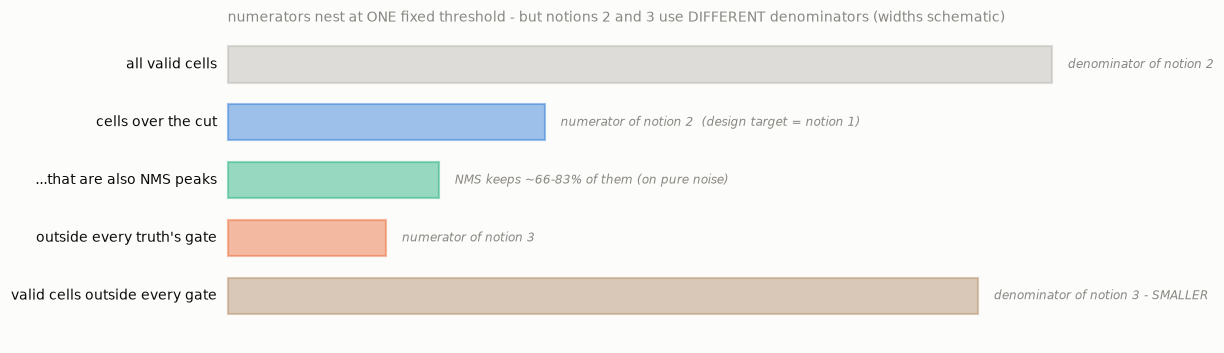

In [22]:
fig, ax = plt.subplots(figsize=(12.4, 3.9))
ax.set_xlim(0, 100); ax.set_ylim(0, 10); ax.axis("off")

bars = [("all valid cells", 78, GREY, "denominator of notion 2"),
        ("cells over the cut", 30, BLUE, "numerator of notion 2  (design target = notion 1)"),
        ("...that are also NMS peaks", 20, AQUA, "NMS keeps ~66-83% of them (on pure noise)"),
        ("outside every truth's gate", 15, ORANGE, "numerator of notion 3"),
        ("valid cells outside every gate", 71, "#b08968", "denominator of notion 3 - SMALLER")]
for i, (label, w, c, note) in enumerate(bars):
    y = 8.4 - i * 1.75
    ax.add_patch(Rectangle((14, y - 0.55), w, 1.1, facecolor=c, alpha=0.45,
                           edgecolor=c, linewidth=1.4))
    ax.text(13, y, label, ha="right", va="center", fontsize=9)
    ax.text(14 + w + 1.5, y, note, va="center", fontsize=8.1, color=MUTED, style="italic")
ax.text(14, 9.7, "numerators nest at ONE fixed threshold - but notions 2 and 3 use DIFFERENT "
        "denominators (widths schematic)", fontsize=9, color=MUTED)
plt.show()

*<span style='color:#6b6b6b'>The NUMERATORS nest: every notion-3 false alarm is also a notion-2 one at the same threshold. The DENOMINATORS do not match, because notion 3 removes the guard cells. So the two rates cannot be ordered in general — see below for the case where they can.</span>*

**⚠️ When notion 3 ≤ notion 2, and when that does not follow.** The *numerator* of notion 3 is a
subset of notion 2's at the same threshold — a surviving local maximum outside every gate is also a
cell above threshold. But notion 3 also uses a **smaller denominator**, since guard cells are
removed. Two ratios whose numerator *and* denominator both shrink cannot be ordered without knowing
by how much.

**The ordering holds when the denominators are equal**, which is exactly the case on **target-free
frames**: with no truths there is no guard region, so both notions divide by the same count and
notion 3 ≤ notion 2 follows directly. That is the pure-noise calibration setting the survival
fractions below are measured in, and it is where the comparison is made.

On target-bearing frames both effects are present and the relationship has to be measured rather
than assumed.

In [23]:
AUD = pd.read_csv(ROOT / "results" / "cfar_alpha_audit.csv").set_index("method")
surv = (AUD.pfa_peaks_verifyseed_at_current / AUD.pfa_cells_verifyseed_at_current)
rel = pd.DataFrame({
    "measured per-cell (notion 2)": AUD.pfa_cells_verifyseed_at_current,
    "measured post-NMS (notion 3)": AUD.pfa_peaks_verifyseed_at_current,
    "NMS survival fraction": surv,
    "per-cell rate behind a post-NMS 1e-4": TARGET_PFA / surv,
})
display(rel.style.format({"measured per-cell (notion 2)": "{:.3e}",
                          "measured post-NMS (notion 3)": "{:.3e}",
                          "NMS survival fraction": "{:.3f}",
                          "per-cell rate behind a post-NMS 1e-4": "{:.3e}"}))
print("Measured on PURE-NOISE frames at a held-out seed (scripts/cfar_alpha_audit.py) -- no")
print("targets, so no guard region, so both notions share a denominator and are comparable.")
print(f"Survival runs {surv.min():.2f}-{surv.max():.2f}, so a post-NMS Pfa of 1e-4 sits behind a")
print(f"per-cell rate of {(TARGET_PFA / surv).min():.2e}-{(TARGET_PFA / surv).max():.2e}.")
print()
print("NOTE the SPREAD across these four. All four call the same all_peaks() at the same NMS")
print(f"radius, and their survival fractions still differ by a factor of {surv.max() / surv.min():.2f}.")
print("Sharing the NMS implementation does NOT imply sharing a survival fraction -- it depends on")
print("how peaked the score map is, which is a property of the detector. See 5.2.")

,measured per-cell (notion 2),measured post-NMS (notion 3),NMS survival fraction,per-cell rate behind a post-NMS 1e-4
method,,,,
CA,2.368e-04,1.687e-04,0.712,1.404e-04
GO,7.756e-05,5.978e-05,0.771,1.297e-04
OS,1.324e-05,1.097e-05,0.829,1.207e-04
SO,6.545e-04,4.302e-04,0.657,1.522e-04


Measured on PURE-NOISE frames at a held-out seed (scripts/cfar_alpha_audit.py) -- no
targets, so no guard region, so both notions share a denominator and are comparable.
Survival runs 0.66-0.83, so a post-NMS Pfa of 1e-4 sits behind a
per-cell rate of 1.21e-04-1.52e-04.

NOTE the SPREAD across these four. All four call the same all_peaks() at the same NMS
radius, and their survival fractions still differ by a factor of 1.26.
Sharing the NMS implementation does NOT imply sharing a survival fraction -- it depends on
how peaked the score map is, which is a property of the detector. See 5.2.


### 5.2 Where the distinction bites — and why the CFAR-vs-DL comparison is unaffected

**It bites whenever a measured rate is compared against an *absolute* per-cell reference.** The
square-law theory curve in `cfar_baseline.ipynb` §5 is a statement about one cell crossing a
threshold at a per-cell rate, so comparing a post-NMS rate against it understates the CFAR loss.
That is why the number is quoted both as plotted and as corrected.

**It does not affect the CFAR-vs-DL comparison — but not for the reason one might assume.** It would
be wrong to argue that the NMS offset is common-mode and divides out because both arms run the same
`all_peaks()` at the same radius. **Running the same NMS does not imply the same survival fraction.**
Survival depends on how peaked a detector's score map is, not on the suppression code: the table
above shows four CFAR variants sharing one `all_peaks()` call whose survival fractions still differ
substantially, and §1.1 showed the network's above-threshold response is far broader than CFAR's
(≈10 cells per detection against ≈2), so there is every reason to expect its survival fraction to
differ again.

**The actual argument is simpler and needs no such assumption.** Both detectors are matched
**directly at the same final post-NMS, guard-excluded Pfa** — notion 3 is the quantity being
equalised, measured on each arm's own reported detections. Whatever per-cell rates sit behind those
matched post-NMS rates may well differ between the arms; that is irrelevant, because no reported
comparison is made at the per-cell level. The fairness comes from equalising the quantity that is
actually reported, not from a cancellation.

### 5.3 In summary

In practice, these three Pfa values describe three different stages of the same detector rather than
three interchangeable numbers. The design Pfa is the target used to choose or calibrate a CFAR
threshold; the measured pre-NMS Pfa tells us how many cells actually cross that threshold; and the
measured post-NMS, guard-excluded Pfa tells us how many false target reports remain after the
detector's full post-processing. The CFAR-versus-DL comparison is made using this final quantity,
because it reflects the false-alarm burden of the detections that would actually be reported. The two
methods therefore do not need to have the same raw cell-crossing rate or the same NMS survival
fraction — they only need to be matched at the same final measured post-NMS Pfa before their Pd
values are compared.

**Rule for the write-up:** never write "Pfa" unqualified. Say which of the three.

---
## 6 · Localization error

**The question:** a detector found the target. How well did it place it?

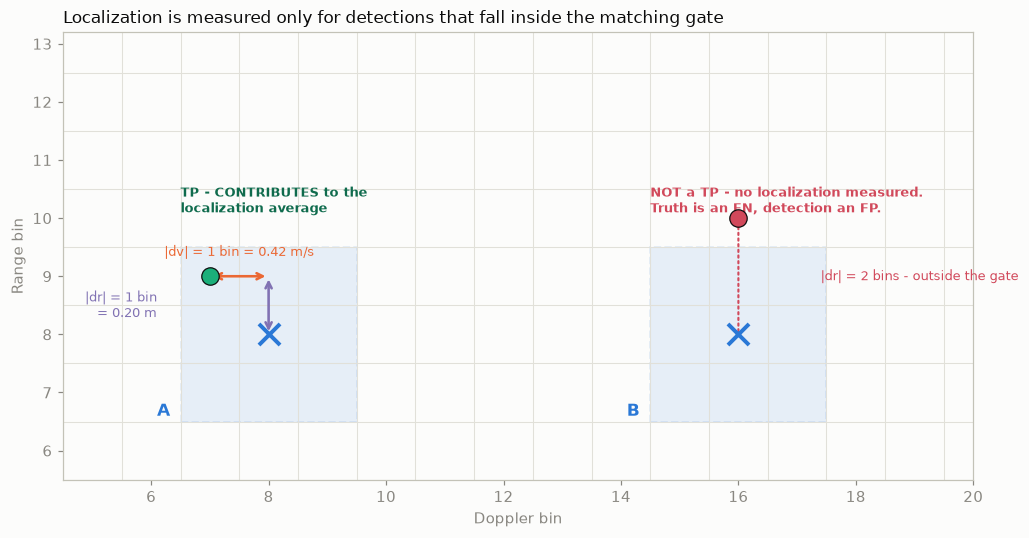

gate +/-1:  TP=1  FP=1  FN=1
localization pairs recorded: 1  (dr=[1], dv=[-1])
Pair B contributes nothing to the localization average -- it is not a TP.


In [24]:
# Two INVENTED truth/detection pairs on a small grid, scored by the project's own evaluate_frame.
LOC_SHAPE = (20, 24)
LOC_T = np.array([[8.0, 8.0], [8.0, 16.0]])      # A (matched), B (not matched at +/-1)
LOC_D = np.array([[9.0, 7.0], [10.0, 16.0]])
EV_LOC = evaluate_frame(LOC_D, LOC_T, LOC_SHAPE, GATE)

fig, ax = plt.subplots(figsize=(9.6, 5.0))
for x in range(4, 21):
    ax.axvline(x - 0.5, color=GRID, linewidth=0.7)
for y in range(5, 14):
    ax.axhline(y - 0.5, color=GRID, linewidth=0.7)

matched = set(EV_LOC.matched_truth_idx)
for k, ((t_r, t_v), (d_r, d_v)) in enumerate(zip(LOC_T, LOC_D)):
    is_tp = k in matched
    ax.add_patch(Rectangle((t_v - GATE.tol_v - 0.5, t_r - GATE.tol_r - 0.5),
                           2 * GATE.tol_v + 1, 2 * GATE.tol_r + 1, facecolor=BLUE,
                           alpha=0.10, edgecolor=BLUE, linestyle="--", linewidth=1.3))
    ax.scatter(t_v, t_r, marker="x", s=190, color=BLUE, linewidths=2.6, zorder=5)
    ax.scatter(d_v, d_r, marker="o", s=130, color=AQUA if is_tp else RED,
               edgecolor=INK, linewidths=0.8, zorder=5)

    if is_tp:
        j = EV_LOC.matched_truth_idx.index(k)
        dr, dv = EV_LOC.dr[j], EV_LOC.dv[j]
        ax.annotate("", xy=(t_v, d_r), xytext=(t_v, t_r),
                    arrowprops=dict(arrowstyle="<->", color=PURPLE, linewidth=1.7))
        ax.annotate("", xy=(d_v, d_r), xytext=(t_v, d_r),
                    arrowprops=dict(arrowstyle="<->", color=ORANGE, linewidth=1.7))
        ax.text(t_v - 1.9, (t_r + d_r) / 2, f"|dr| = {abs(dr)} bin\n= {abs(dr) * RES_R:.2f} m",
                fontsize=8.5, color=PURPLE, ha="right", va="center")
        ax.text((t_v + d_v) / 2, d_r + 0.35,
                f"|dv| = {abs(dv)} bin = {abs(dv) * RES_V:.2f} m/s",
                fontsize=8.5, color=ORANGE, ha="center")
        ax.text(t_v - 1.5, t_r + 2.1, "TP - CONTRIBUTES to the\nlocalization average",
                fontsize=8.5, color="#0f6b4d", weight="bold")
    else:
        ax.annotate("", xy=(d_v, d_r), xytext=(t_v, t_r),
                    arrowprops=dict(arrowstyle="-", color=RED, linewidth=1.4, linestyle=":"))
        ax.text(t_v + 1.4, (t_r + d_r) / 2,
                f"|dr| = {int(abs(d_r - t_r))} bins - outside the gate",
                fontsize=8.5, color=RED, va="center")
        ax.text(t_v - 1.5, t_r + 2.1,
                "NOT a TP - no localization measured.\nTruth is an FN, detection an FP.",
                fontsize=8.5, color=RED, weight="bold")

ax.text(6.1, 6.6, "A", fontsize=11, color=BLUE, weight="bold")
ax.text(14.1, 6.6, "B", fontsize=11, color=BLUE, weight="bold")
ax.set_xlim(4.5, 20.0); ax.set_ylim(5.5, 13.2)
ax.set_xlabel("Doppler bin"); ax.set_ylabel("Range bin")
ax.set_title("Localization is measured only for detections that fall inside the matching gate",
             loc="left", fontsize=11)
ax.grid(False)
plt.tight_layout(); plt.show()

print(f"gate +/-{GATE.tol_r}:  TP={EV_LOC.tp}  FP={EV_LOC.fp}  FN={EV_LOC.fn}")
print(f"localization pairs recorded: {len(EV_LOC.dr)}  "
      f"(dr={EV_LOC.dr}, dv={EV_LOC.dv})")
print("Pair B contributes nothing to the localization average -- it is not a TP.")

*<span style='color:#6b6b6b'>The left detection falls inside the ±1 matching gate and is therefore a TP; its range and Doppler offsets contribute to the localization average. The right detection lies outside the gate, so the pair is not included in localization error. Instead, the target is missed and the unmatched detection is handled by the FP/FN counting rules.</span>*

**Three properties of this metric that must be stated when it is quoted.**

1. **It is computed over matched TP pairs only.** A target nobody detected contributes nothing.
2. **It is bounded by the gate.** A detection displaced further than the tolerance is not recorded as
   a large error — the pair simply fails to match, and shows up as lost Pd instead. Concretely, the
   per-axis localization errors are bounded by 1 bin at the ±1 gate, or 3 bins at the ±3 gate. Note
   this is a *per-axis* bound: the combined Euclidean distance can exceed it, reaching √2 ≈ 1.41 bins
   at the ±1 gate when both axes are off by one. Both gates are reported for this reason.
3. **It is conditioned on detection**, which makes it vulnerable to a selection effect: a detector
   that only finds easy targets is measuring its precision on easy targets. That is §6.1.

In [25]:
bins = np.array([0, 1, 2, 3])
conv = pd.DataFrame({"bins": bins,
                     "range (m)": bins * RES_R,
                     "Doppler (m/s)": bins * RES_V}).set_index("bins")
display(conv.round(3))
print(f"1 range bin = {RES_R:.4f} m,  1 Doppler bin = {RES_V:.4f} m/s")
print(f"per-axis bound at the +/-1 gate: 1 bin; worst combined Euclidean distance: "
      f"{np.hypot(1, 1):.3f} bins")
print(f"per-axis bound at the +/-3 gate: 3 bins; worst combined Euclidean distance: "
      f"{np.hypot(3, 3):.3f} bins")

,range (m),Doppler (m/s)
bins,,
0,0.000,0.00
1,0.195,0.42
2,0.390,0.84
3,0.586,1.26


1 range bin = 0.1952 m,  1 Doppler bin = 0.4201 m/s
per-axis bound at the +/-1 gate: 1 bin; worst combined Euclidean distance: 1.414 bins
per-axis bound at the +/-3 gate: 3 bins; worst combined Euclidean distance: 4.243 bins


### 6.2 In summary

Localization error asks where the detector placed a target after it successfully found it, rather
than whether the target was detected at all. For every detection that is successfully matched to a
ground-truth target, we calculate the absolute difference in range and Doppler bins. These errors are
collected across all matched targets in the evaluated data and then averaged, so the metric is
target-weighted rather than frame-weighted: a frame containing three matched targets contributes
three localization measurements, while a frame with no matched targets contributes none. A target
whose detection falls outside the matching gate does not contribute a large localization error;
instead, it fails to match and is handled through the detection metrics. Localization error is
therefore measured only over true-positive pairs and is bounded by the matching tolerance used.

### 6.1 Does the localization gap survive on the common detected subset?

**The question:** localization is averaged over each arm's *own* detections. If one arm detects a
harder subset of targets, its localization average is measured on a harder population. Is a measured
localization difference genuine, or an artefact of that?

**The check:** restrict both arms to the targets **both** detected, at the same matched operating
point, per condition, and recompute. Every target then contributes to both averages or to neither.
Formed per DL seed against CFAR's set and averaged over the eight seeds, since each seed detects a
slightly different set.

⚠️ **Post-hoc.** This is not in `docs/test_preregistration.md`; it is listed there and in the
comparison notebook as a limitation deliberately *not* run before the test split was read. It
validates the metric's interpretation. It does not replace the pre-registered number.

In [26]:
COMMON = pd.read_csv(DLR / "localization_common_frozen_ep021_test.csv").set_index("condition")
FULL = pd.read_csv(DLR / "localization_frozen_ep021_test.csv")
f1 = FULL[FULL.gate == 1]

rows = []
for cond in COMMON.index:
    s = f1[f1.group == cond].set_index("method")
    if "DL" not in s.index:
        continue
    cfm = COMMON.loc[cond, "cfar_method"]
    ref = s.drop("DL")
    dv_all = (s.loc["DL", "dv_bins"] /
              (ref.dv_bins.min() if cond == "ALL" else ref.loc[cfm, "dv_bins"]))
    dr_all = (s.loc["DL", "dr_bins"] /
              (ref.dr_bins.min() if cond == "ALL" else ref.loc[cfm, "dr_bins"]))
    rows.append(dict(condition=cond,
                     common_frac=COMMON.loc[cond, "n_common"] / COMMON.loc[cond, "n_cfar"],
                     doppler_own_sets=dv_all, doppler_common=COMMON.loc[cond, "ratio_dv"],
                     range_own_sets=dr_all, range_common=COMMON.loc[cond, "ratio_dr"]))

CMP = pd.DataFrame(rows).set_index("condition")
CMP["doppler_shift"] = CMP.doppler_common - CMP.doppler_own_sets
CMP["range_shift"] = CMP.range_common - CMP.range_own_sets
display(CMP.round(3))
print("Ratios are DL error / CFAR error, so >1 means CFAR localises more precisely.")
print("*_own_sets uses each arm's own detected targets; *_common uses only targets BOTH detected.")

,common_frac,doppler_own_sets,doppler_common,range_own_sets,range_common,doppler_shift,range_shift
condition,,,,,,,
clutter,0.811,6.439,8.803,4.595,4.861,2.364,0.266
clutter_edge,0.999,1.620,1.322,3.059,2.853,-0.299,-0.206
isolated,0.992,4.732,4.552,2.511,2.474,-0.180,-0.037
masking,0.958,5.527,5.190,2.470,2.502,-0.337,0.032
mixed,0.959,3.766,3.706,2.031,1.935,-0.060,-0.096
multi,0.984,4.378,4.146,2.254,2.253,-0.231,-0.001
unresolved,0.742,3.195,3.222,1.748,1.819,0.027,0.071
ALL,0.943,3.829,3.628,2.401,2.309,-0.201,-0.092


Ratios are DL error / CFAR error, so >1 means CFAR localises more precisely.
*_own_sets uses each arm's own detected targets; *_common uses only targets BOTH detected.


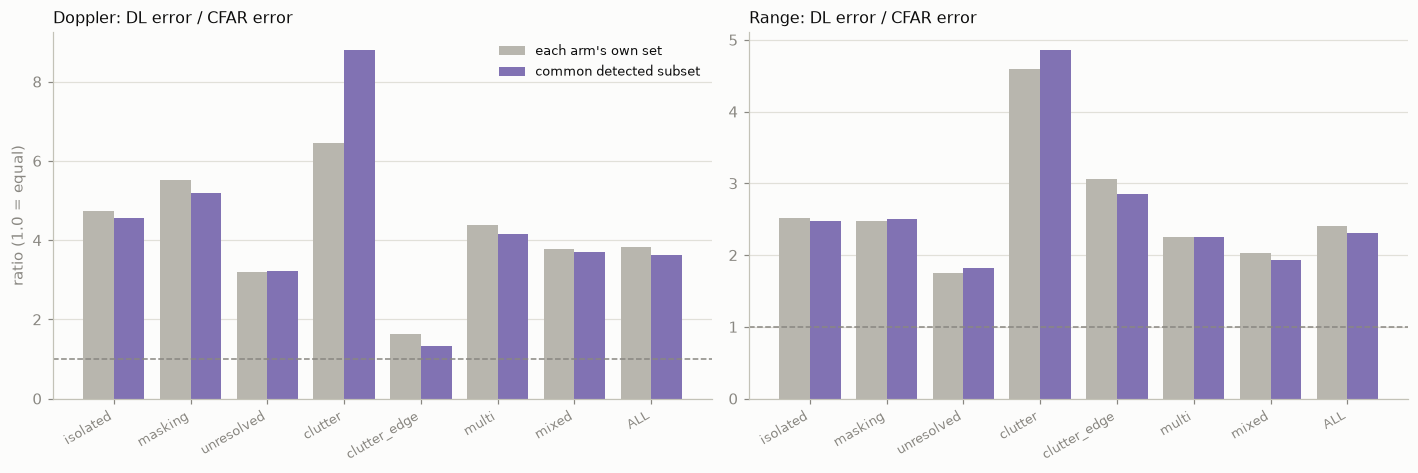

pooled Doppler: 3.83x -> 3.63x on the common subset (-0.20)
pooled range  : 2.40x -> 2.31x (-0.09)
the common subset is 94.3% of the CFAR arm's detected targets

ratio shrinks on 5 of 7 conditions, grows on 2


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.4), sharey=False)
order = [c for c in ORDER if c in CMP.index] + (["ALL"] if "ALL" in CMP.index else [])
x = np.arange(len(order))
for ax, axis, cols in zip(axes, ["Doppler", "Range"],
                          [("doppler_own_sets", "doppler_common"),
                           ("range_own_sets", "range_common")]):
    ax.bar(x - 0.2, CMP.loc[order, cols[0]], width=0.4, color=GREY, label="each arm's own set")
    ax.bar(x + 0.2, CMP.loc[order, cols[1]], width=0.4, color=PURPLE,
           label="common detected subset")
    ax.axhline(1.0, color=MUTED, linewidth=1.0, linestyle="--")
    ax.set_xticks(x); ax.set_xticklabels(order, rotation=30, ha="right", fontsize=8.5)
    ax.set_title(f"{axis}: DL error / CFAR error", loc="left", fontsize=10.5)
    tidy(ax)
axes[0].set_ylabel("ratio (1.0 = equal)")
axes[0].legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

if "ALL" in CMP.index:
    a = CMP.loc["ALL"]
    print(f"pooled Doppler: {a.doppler_own_sets:.2f}x -> {a.doppler_common:.2f}x on the common "
          f"subset ({a.doppler_shift:+.2f})")
    print(f"pooled range  : {a.range_own_sets:.2f}x -> {a.range_common:.2f}x "
          f"({a.range_shift:+.2f})")
    print(f"the common subset is {100 * a.common_frac:.1f}% of the CFAR arm's detected targets")
moved = CMP.drop(index="ALL", errors="ignore")
print(f"\nratio shrinks on {int((moved.doppler_shift < 0).sum())} of {len(moved)} conditions, "
      f"grows on {int((moved.doppler_shift > 0).sum())}")

**The gap is not a selection artefact.** Restricting both arms to the targets they both found
moves the pooled Doppler ratio by only a few percent, and it stays far above 1.0 — the localization
difference is a real difference in precision, not an artefact of the two arms measuring precision on
different populations.

Two details worth carrying into the write-up:

* **The restriction is mild, and that is itself informative.** The CFAR arm's detections are largely
  a subset of the network's, so intersecting removes mostly DL-only targets — the harder ones the
  network found and CFAR missed. Dropping them makes DL's average error *better*, which is why most
  conditions shrink slightly. That is the selection effect, measured: it exists, and it is small.
* **`clutter` moves the other way, and substantially.** It is the condition where the two arms
  overlap least — its common fraction and `unresolved`'s are the only ones far below the 0.96–1.00
  the rest sit at — and the only one where the arms tie on Pd, so each is finding a partly different
  set of targets. The intersection there is a genuinely different population and the ratio is
  correspondingly unstable. (`unresolved` also rises, but by a negligible amount.) Report `clutter`
  localization with that caveat attached.

⚠️ Post-hoc, so it belongs beside the pre-registered number as a robustness check, never in place of
it.

### 6.1a In summary

Because localization is calculated only for targets that a detector successfully finds, the two
methods may initially be averaging their errors over different sets of targets. For example, if DL
detects some difficult targets that CFAR misses, DL's localization average may include harder
examples while CFAR's does not. To check whether this explains the localization gap, we repeat the
calculation using only the targets that both CFAR and DL detected. This gives both methods exactly
the same target population. The localization gap remains on this common detected subset, showing that
CFAR's better localization is not simply caused by it detecting an easier set of targets. This
common-subset analysis is a post-hoc robustness check and therefore supports the original
localization result rather than replacing it.

---
## 7 · ROC, FROC, and "matched measured Pfa"

**The question:** a detector's Pd depends entirely on how freely it is allowed to raise alarms. How
do you compare two detectors that are not naturally at the same setting?

**Sweep the threshold.** `all_peaks()` returns every local maximum with its score, before the
operating threshold is applied (a `score > 0` floor does apply -- see 1.1b).
Raising the threshold gives fewer detections, lower Pd and lower Pfa; lowering it does the reverse.
Tracing that gives a curve, and the comparison is made at a chosen point on it rather than at
whatever threshold each detector happens to come with.

* **ROC** here is Pd against **measured per-cell post-NMS Pfa** (notion 3 of §5.1).
* **FROC** is the same sweep against **false alarms per frame** — the same information on an
  operational axis.

The curves below are from `bench2_val`, exported by `scripts/roc_curve_export.py`. They illustrate
the procedure; they are not the reported comparison.

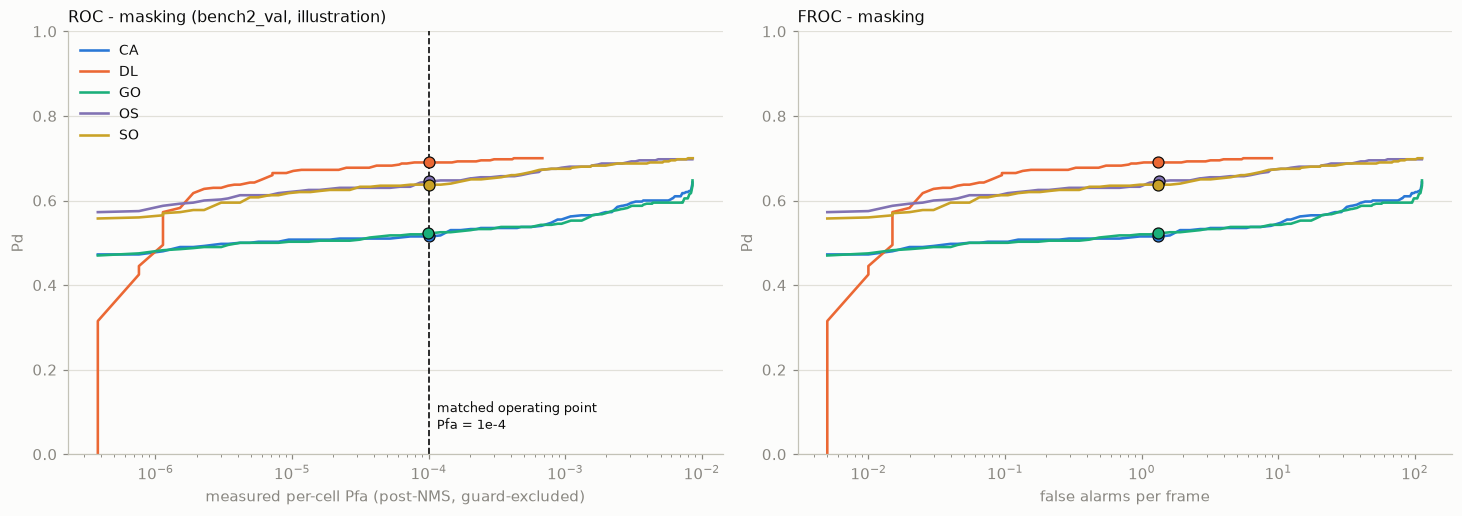

In [28]:
ROC = pd.read_csv(DLR / "roc_curves_val_tol1.csv")
COND = "masking"
sub = ROC[ROC.condition == COND]

fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.8))
for m, g in sub.groupby("method"):
    g = g.sort_values("threshold")
    axes[0].semilogx(g.pfa_per_cell.replace(0, np.nan), g.pd, color=METHOD_COLOR[m],
                     lw=1.7, label=m)
    axes[1].semilogx(g.fa_per_frame.replace(0, np.nan), g.pd, color=METHOD_COLOR[m], lw=1.7)

op = OPP[OPP.condition == COND]
axes[0].axvline(TARGET_PFA, color=INK, linewidth=1.1, linestyle="--")
axes[0].text(TARGET_PFA * 1.15, 0.06, "matched operating point\nPfa = 1e-4", fontsize=8.5)
for _, r in op.iterrows():
    axes[0].scatter(r.measured_pfa, r.pd_measured, s=52, color=METHOD_COLOR[r.method],
                    edgecolor=INK, linewidths=0.8, zorder=5)
    axes[1].scatter(r.fa_per_frame, r.pd_measured, s=52, color=METHOD_COLOR[r.method],
                    edgecolor=INK, linewidths=0.8, zorder=5)

axes[0].set_xlabel("measured per-cell Pfa (post-NMS, guard-excluded)")
axes[1].set_xlabel("false alarms per frame")
for ax in axes:
    ax.set_ylabel("Pd"); ax.set_ylim(0, 1.0); tidy(ax)
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
axes[0].set_title(f"ROC - {COND} (bench2_val, illustration)", loc="left", fontsize=10.5)
axes[1].set_title(f"FROC - {COND}", loc="left", fontsize=10.5)
plt.tight_layout(); plt.show()

*<span style='color:#6b6b6b'>Each dot is where that method is scored. They sit on approximately the same vertical line in the left panel — the achieved Pfa is close to 1e-4 rather than exactly it, which is why §7.1 reports the achieved value beside every operating point. That near-alignment is what 'matched measured Pfa' means, and the vertical spread between the dots is the only thing the comparison reads off.</span>*

### 7.0 In summary

A detector's Pd cannot be interpreted without considering how many false alarms it is allowed to
produce. Lowering the score threshold generally lets more detections through, increasing both the
opportunity to detect real targets and the number of false alarms, while raising the threshold does
the opposite. We therefore sweep the threshold for each detector to obtain a curve relating Pd to its
measured false-alarm burden. The CFAR and DL methods are not compared at the same numerical score
threshold, because their scores have different meanings and scales. Instead, each method is placed at
approximately the same measured post-NMS Pfa of $10^{-4}$, and their Pd values are compared there.
The corresponding FROC shows the same threshold sweep using false alarms per frame, which expresses
the false-alarm burden in a more operational form.

### 7.1 How the operating point is chosen, and why Pd is measured rather than interpolated

Two steps, deliberately different in kind:

1. **The threshold** is found by interpolating the swept curve against **log** Pfa (Pfa falls roughly
   exponentially with the threshold, so linear interpolation overshoots). Tied Pfa values are
   collapsed first, because on clean conditions a whole span of thresholds gives the *same* measured
   Pfa and interpolation would otherwise pick an arbitrary partner.
2. **Pd is then measured at that threshold** — every frame re-scored — rather than read off the
   interpolated curve. Interpolating Pd would report a value no run of the detector ever produced.

The two agree closely, which is a check that the grid is dense enough, not a reason to skip step 2:

In [29]:
show = OPP[["condition", "method", "threshold", "pd_interp", "pd_measured",
            "measured_pfa", "ratio_to_target"]].copy()
show["|difference|"] = (show.pd_measured - show.pd_interp).abs()
display(show.round({"threshold": 3, "pd_interp": 4, "pd_measured": 4,
                    "ratio_to_target": 3, "|difference|": 4})
        .style.format({"measured_pfa": "{:.3e}"}).hide(axis="index"))
print(f"max |pd_measured - pd_interp| = {show['|difference|'].max():.4f}")
print(f"achieved Pfa / target: {show.ratio_to_target.min():.3f} to "
      f"{show.ratio_to_target.max():.3f}  (a protocol check -- if this drifted, the arms would")
print("not be at a common operating point and no Pd difference would be interpretable)")

condition,method,threshold,pd_interp,pd_measured,measured_pfa,ratio_to_target,|difference|
isolated,CA,10.061000,0.708300,0.710000,9.957e-05,0.996000,0.001700
isolated,GO,9.142000,0.699000,0.700000,9.881e-05,0.988000,0.001000
isolated,OS,7.260000,0.710000,0.710000,9.843e-05,0.984000,0.000000
isolated,SO,12.161000,0.700000,0.700000,1.007e-04,1.007000,0.000000
isolated,DL,1.400000,0.729200,0.730000,9.995e-05,0.999000,0.000800
masking,CA,9.968000,0.515000,0.515000,1.004e-04,1.004000,0.000000
masking,GO,9.202000,0.522000,0.522500,9.964e-05,0.996000,0.000500
masking,OS,7.206000,0.644600,0.645000,1.012e-04,1.012000,0.000400
masking,SO,12.281000,0.637500,0.637500,1.008e-04,1.008000,0.000000
masking,DL,1.392000,0.690000,0.690000,1.004e-04,1.004000,0.000000


max |pd_measured - pd_interp| = 0.0017
achieved Pfa / target: 0.977 to 1.012  (a protocol check -- if this drifted, the arms would
not be at a common operating point and no Pd difference would be interpretable)


**The same check on the reported split.** The table above is `bench2_val`, used here as an
illustration. The equivalent check on `bench2_test` was produced by the pre-registered run and is
read from its cached artefact — if these had drifted, no Pd difference in the report would be
interpretable.

In [30]:
PFA_T = pd.read_csv(DLR / "measured_pfa_frozen_ep021_test_tol1.csv")
piv = PFA_T.pivot(index="condition", columns="method", values="ratio_to_target")
piv = piv.reindex([c for c in ORDER if c in piv.index])
display(piv.round(4))
print(f"achieved Pfa / target, bench2_test: {PFA_T.ratio_to_target.min():.4f} to "
      f"{PFA_T.ratio_to_target.max():.4f}")
print(f"worst deviation from the 1e-4 target: "
      f"{100 * (PFA_T.ratio_to_target - 1).abs().max():.2f}%  "
      f"across {PFA_T.method.nunique()} methods x {PFA_T.condition.nunique()} conditions")

method,CA,DL,GO,OS,SO
condition,,,,,
isolated,1.0070,0.9992,0.9957,1.0108,0.9900
masking,0.9869,0.9982,1.0001,0.9869,1.0134
unresolved,1.0073,0.9976,0.9979,0.9884,1.0054
clutter,0.9831,0.9978,0.9945,1.0172,0.9907
clutter_edge,0.9941,0.9996,0.9979,0.9903,0.9828
multi,0.9810,1.0012,0.9905,1.0152,0.9924
mixed,1.0042,1.0016,1.0004,0.9928,0.9909


achieved Pfa / target, bench2_test: 0.9810 to 1.0172
worst deviation from the 1e-4 target: 1.90%  across 5 methods x 8 conditions


*<span style='color:#6b6b6b'>Every entry within a couple of percent of 1.0 — the operating points genuinely matched, so the Pd comparisons are like-for-like. This is the check that licenses everything else.</span>*

### 7.1a In summary

Because the threshold sweep evaluates only a finite set of score values, there is not always a
sampled threshold that produces exactly the target Pfa of $10^{-4}$. The operating threshold is
therefore estimated by interpolating between nearby points using log Pfa, which better reflects the
approximately exponential relationship between threshold and false-alarm rate. Only the threshold is
interpolated: once it is chosen, the detector is evaluated again at that actual threshold and Pd is
measured directly from the resulting detections. The achieved Pfa is then checked against the
$10^{-4}$ target to verify that the different methods really are being compared at essentially the
same false-alarm burden.

### 7.2 ⚠️ The threshold is an evaluation oracle

**The threshold is selected separately for each method and each condition, using that
method-condition pair's own measured ROC.**

That makes it an **evaluation-oracle operating point**. It answers a specific, legitimate question —
*given that both detectors are placed at the same false-alarm burden, which discriminates better?* —
and it is the right question for isolating discrimination from threshold setting.

It is **not** a demonstration that one fixed deployment threshold holds Pfa = 1e-4 across
environments. A deployed system does not know which scenario it is looking at, and cannot re-derive
its threshold per scene from labelled data. Holding a false-alarm rate constant under changing
clutter *without* that knowledge is precisely the property CFAR is named for, and nothing here tests
whether the network has it.

That gap is the motivation for the fixed-threshold / CFAR-ness experiment: run every method at a
**single** threshold across all conditions and measure how far the achieved Pfa wanders. Until that
is done, no claim of CFAR-like behaviour by the network is supported by this protocol.

### 7.2a In summary

The matched-Pfa threshold used here is an evaluation operating point rather than a deployment
threshold. A separate threshold is selected for each method and each condition using that
method-condition pair's measured ROC, which allows the experiment to ask a controlled question: if
the methods are given the same observed false-alarm burden, which one detects more targets? This
isolates discrimination ability from threshold-setting ability. However, a deployed detector does not
know the true scenario or have labelled data available to rebuild its ROC and adjust its threshold
for every environment. The matched-Pfa results therefore do not show that DL can maintain a constant
false-alarm rate on its own; that would require a separate fixed-threshold experiment across changing
conditions.

---
## 8 · Uncertainty: the paired frame bootstrap

**The question:** the measured difference in Pd is some number. How much of it is real?

**The idea.** The original test compares CFAR and DL on exactly the same test frames. The
bootstrap is not used because the two methods saw different data; it is used to check how much the
measured difference depends on the particular test frames that happened to be generated. To do this,
the existing test frames are repeatedly resampled with replacement, creating many slightly different
versions of the test set. For every resample, CFAR and DL are evaluated on the exact same selected
frames, and the difference in Pd is calculated again. Repeating this 2,000 times shows whether the
observed DL-versus-CFAR difference is stable or whether it changes a lot when the mix of test frames
changes.

**Why "paired".** The bootstrap is called paired because both detectors always use the same
resampled frame indices. If a difficult frame appears several times in one bootstrap sample, it
appears several times for both CFAR and DL. This keeps the comparison fair and prevents differences
in frame difficulty from being mistaken for differences between the detectors.

The spread of those 2,000 differences is **the uncertainty in the Pd difference caused by using a
finite sample of test frames**.

*(The approach this replaced — a one-sample t-test of the DL seeds against CFAR's Pd as a
**constant** — treated CFAR as exact when it is one draw over the same finite frames, and produced
overconfident p-values throughout.)*

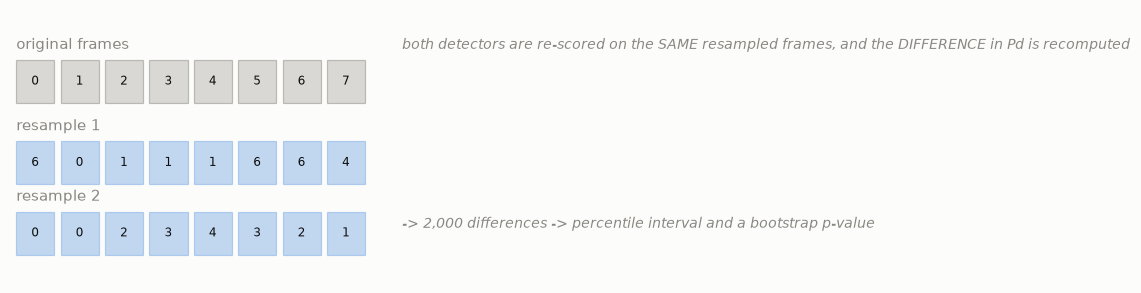

In [31]:
fig, ax = plt.subplots(figsize=(12.4, 3.2))
ax.set_xlim(0, 100); ax.set_ylim(0, 10); ax.axis("off")
rng_demo = np.random.default_rng(3)
orig = np.arange(8)
ax.text(0.5, 8.6, "original frames", fontsize=9.5, color=MUTED)
for i, f in enumerate(orig):
    ax.add_patch(Rectangle((0.5 + i * 4.2, 6.6), 3.6, 1.6, facecolor=GREY, alpha=0.5,
                           edgecolor=MUTED, linewidth=0.8))
    ax.text(2.3 + i * 4.2, 7.4, str(f), ha="center", va="center", fontsize=8)
for row, y in enumerate([3.6, 1.0]):
    draw = rng_demo.integers(0, 8, 8)
    ax.text(0.5, y + 2.0, f"resample {row + 1}", fontsize=9.5, color=MUTED)
    for i, f in enumerate(draw):
        ax.add_patch(Rectangle((0.5 + i * 4.2, y), 3.6, 1.6, facecolor=BLUE, alpha=0.28,
                               edgecolor=BLUE, linewidth=0.8))
        ax.text(2.3 + i * 4.2, y + 0.8, str(f), ha="center", va="center", fontsize=8)
ax.text(37, 8.6, "both detectors are re-scored on the SAME resampled frames, and the "
                 "DIFFERENCE in Pd is recomputed", fontsize=9, color=MUTED, style="italic")
ax.text(37, 2.0, "-> 2,000 differences -> percentile interval and a bootstrap p-value",
        fontsize=9, color=MUTED, style="italic")
plt.show()

### 8.1 Best-CFAR uncertainty — re-selecting the winner inside each replicate

**The question:** each condition is reported against "the best CFAR variant". That variant is chosen
once, on the full data, and then treated as certain. On conditions where the top two variants are
within a few thousandths of Pd, is that choice really certain?

**The fix:** re-select the best CFAR variant **inside every bootstrap replicate**, on that
replicate's frames, and take the difference against whichever variant wins there. Uncertainty about
*which* classical detector is strongest is then carried by the interval instead of assumed away.
Both procedures are run on the *same* resamples, so any widening is attributable to the re-selection
and not to bootstrap noise.

⚠️ Re-selection is **conservative for DL by construction**: taking a maximum over four variants on
the same frames used to score them biases the CFAR arm slightly up. It cannot manufacture a DL win.

⚠️ **What the bootstrap does and does not cover.** It only changes which test frames are sampled.
The detector models and the operating thresholds remain fixed, so the interval mainly measures
uncertainty caused by the finite test dataset. It does not include all possible uncertainty from
retraining the network or choosing a new threshold — in particular the threshold is computed once per
method per condition and is not re-derived inside each replicate, which would cost roughly 200× the
compute.

**In plain terms.** For each condition, DL is compared with the best-performing CFAR variant.
However, when two CFAR variants have very similar Pd values, the identity of the best one may change
if the test frames change slightly. To check this, the best CFAR variant is selected again inside
every bootstrap resample. DL is then compared with whichever CFAR variant performs best on that
particular resampled set of frames. This makes the check conservative for DL because CFAR is always
given its strongest variant in each resample.

In [32]:
RES = pd.read_csv(DLR / "bootstrap_reselect_frozen_ep021_test_tol1.csv").set_index("condition")
RES = RES.reindex([c for c in ORDER if c in RES.index])
ALPHA_BONF = 0.05 / len(RES)

view = pd.DataFrame({
    "best CFAR": RES.cfar_method_fixed,
    "diff": RES.diff_observed,
    "CI (fixed winner)": [f"[{a:+.3f}, {b:+.3f}]" for a, b in zip(RES.ci_lo_fixed, RES.ci_hi_fixed)],
    "CI (re-selected)": [f"[{a:+.3f}, {b:+.3f}]" for a, b in
                         zip(RES.ci_lo_reselect, RES.ci_hi_reselect)],
    "width x": RES.width_ratio,
    "winner held": RES.reselect_share_winner,
    "p (fixed)": [fmt_p(p, N_BOOT) for p in RES.p_fixed],
    "p (re-sel)": [fmt_p(p, N_BOOT) for p in RES.p_reselect],
    "sig (fixed)": RES.sig_fixed,
    "sig (re-sel)": RES.sig_reselect,
})
display(view.round({"diff": 4, "width x": 2, "winner held": 2}))
print(f"Bonferroni alpha = {ALPHA_BONF:.4f} over {len(RES)} conditions.")
print(f"verdicts changed : {int(RES.verdict_changed.sum())} of {len(RES)}")
print(f"intervals widened: {int((RES.width_ratio > 1).sum())} of {len(RES)} "
      f"(width ratio {RES.width_ratio.min():.3f} to {RES.width_ratio.max():.3f})")
print(f"least stable winner: {RES.reselect_share_winner.idxmin()} "
      f"({RES.reselect_share_winner.min():.0%} of replicates)")
print("'winner held' is the fraction of replicates in which the globally-selected variant still "
      "won;\na value below 1.0 is selection uncertainty the original procedure ignored.")

,best CFAR,diff,CI (fixed winner),CI (re-selected),width x,winner held,p (fixed),p (re-sel),sig (fixed),sig (re-sel)
condition,,,,,,,,,,
isolated,CA,0.0581,"[+0.036, +0.082]","[+0.036, +0.082]",0.99,0.96,< 0.001,< 0.001,True,True
masking,OS,0.0511,"[+0.037, +0.065]","[+0.037, +0.065]",1.00,1.00,< 0.001,< 0.001,True,True
unresolved,CA,0.0119,"[+0.004, +0.020]","[+0.004, +0.019]",0.95,0.71,0.001,0.002,True,True
clutter,GO,-0.0023,"[-0.019, +0.012]","[-0.019, +0.012]",0.99,0.79,0.793,0.731,False,False
clutter_edge,OS,0.3017,"[+0.267, +0.337]","[+0.267, +0.337]",1.00,0.99,< 0.001,< 0.001,True,True
multi,CA,0.0446,"[+0.034, +0.056]","[+0.034, +0.056]",1.00,0.94,< 0.001,< 0.001,True,True
mixed,GO,0.1031,"[+0.082, +0.124]","[+0.082, +0.124]",1.00,1.00,< 0.001,< 0.001,True,True


Bonferroni alpha = 0.0071 over 7 conditions.
verdicts changed : 0 of 7
intervals widened: 0 of 7 (width ratio 0.952 to 1.000)
least stable winner: unresolved (71% of replicates)
'winner held' is the fraction of replicates in which the globally-selected variant still won;
a value below 1.0 is selection uncertainty the original procedure ignored.


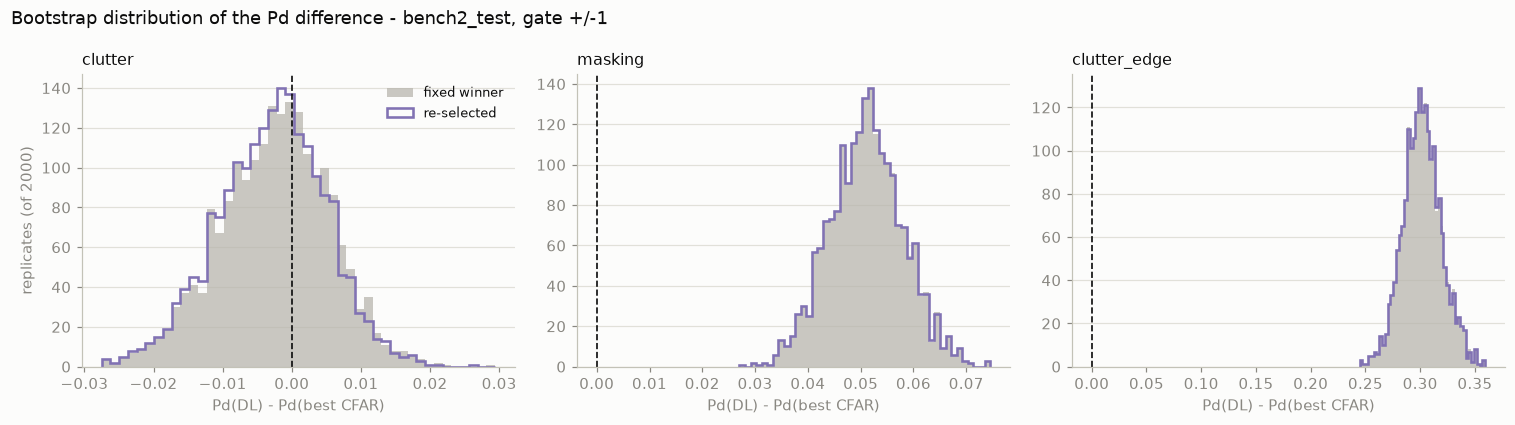

In [33]:
D = np.load(DLR / "bootstrap_reselect_frozen_ep021_test_tol1_diffs.npz")
assert int(D["n_boot"]) == N_BOOT, "the stored replicate count disagrees with N_BOOT"
show_conds = [c for c in ["clutter", "masking", "clutter_edge"] if f"{c}__fixed" in D]

fig, axes = plt.subplots(1, len(show_conds), figsize=(4.6 * len(show_conds), 3.9))
for ax, cond in zip(np.atleast_1d(axes), show_conds):
    lo = min(D[f"{cond}__fixed"].min(), D[f"{cond}__reselect"].min())
    hi = max(D[f"{cond}__fixed"].max(), D[f"{cond}__reselect"].max())
    edges = np.linspace(lo, hi, 46)
    ax.hist(D[f"{cond}__fixed"], bins=edges, color=GREY, alpha=0.75, label="fixed winner")
    ax.hist(D[f"{cond}__reselect"], bins=edges, histtype="step", color=PURPLE, linewidth=1.7,
            label="re-selected")
    ax.axvline(0, color=INK, linewidth=1.1, linestyle="--")
    ax.set_title(cond, loc="left", fontsize=10.5)
    ax.set_xlabel("Pd(DL) - Pd(best CFAR)")
    tidy(ax)
np.atleast_1d(axes)[0].set_ylabel(f"replicates (of {N_BOOT})")
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=8.5)
fig.suptitle("Bootstrap distribution of the Pd difference - bench2_test, gate +/-1",
             x=0.005, ha="left", fontsize=11.5)
plt.tight_layout(); plt.show()

*<span style='color:#6b6b6b'>The dashed line is zero difference. A distribution that sits clear of it is a difference the frame sample supports; one that straddles it is not. Re-selection shifts mass toward CFAR — the conservative direction — and barely changes the spread.</span>*

**What the comparison shows, and why it is not the expected answer.**

The selection uncertainty is real: on the conditions where the classical variants are closest, the
globally-chosen winner loses its crown in a substantial minority of replicates (`winner held` in the
table above). The obvious prediction is that carrying that uncertainty widens the intervals.

**It does not.** The intervals are essentially unchanged, and where they move at all they move
slightly *tighter*. Two things are happening, and they are worth separating:

* **A downward shift, as expected.** Taking the maximum over four variants on each replicate raises
  the CFAR arm a little, so the difference falls. This is the winner's-curse bias flagged above, and
  it runs against DL.
* **No extra spread, because the alternatives are close.** Re-selection only matters when the
  ranking flips — and the ranking flips *precisely when the variants are within noise of each
  other*, where swapping one for another changes Pd by almost nothing. The uncertainty about which
  variant is best turns out to be uncertainty about a choice that barely matters.

So the honest conclusion is not "the original intervals were fine by luck", nor is it that they are
now proven sound. It is the narrower statement that **accounting for uncertainty in which CFAR
variant is best did not materially change the confidence intervals** — because the quantity being
conditioned on is one the comparison is insensitive to. The intervals remain optimistic in the way
flagged above, since threshold-selection uncertainty is still not propagated. This is the kind of
check that is only convincing when it is actually run.

**In plain terms.** The winning CFAR variant does change in some bootstrap samples, but the
final confidence intervals barely change. This happens because the CFAR variants usually switch
places only when their Pd values are already very close. Therefore, there is some uncertainty about
which CFAR method is technically the best, but that uncertainty has very little effect on the overall
DL-versus-CFAR comparison.

---

**The takeaway for §8 as a whole.** In simple terms, the bootstrap asks: *if our test dataset had
contained a slightly different mix of frames from the same generator, would we still reach roughly
the same conclusion about DL versus CFAR?*

---
## 9 · Seven comparisons, not one

**The question:** the comparison is made on seven scenarios. What does a p-value mean when you ask
seven times?

**Bonferroni.** We compare DL and CFAR separately on seven conditions, so we are performing
seven statistical tests rather than only one. Normally, a result with $p < 0.05$ may be called
statistically significant. However, when several tests are performed, there are more chances for at
least one result to appear significant just by random variation. We therefore use the Bonferroni
correction and divide 0.05 by the seven comparisons:

$$\alpha_\text{corrected} = \frac{0.05}{7} \approx 0.0071$$

A scenario-wise difference is therefore called statistically significant only when $p < 0.0071$. The
commonly quoted roughly 30% chance of at least one false positive assumes seven *independent* tests;
the Bonferroni correction itself does not require the tests to be independent.

It is stated in the method rather than applied silently, because it changes which conditions count as
wins.

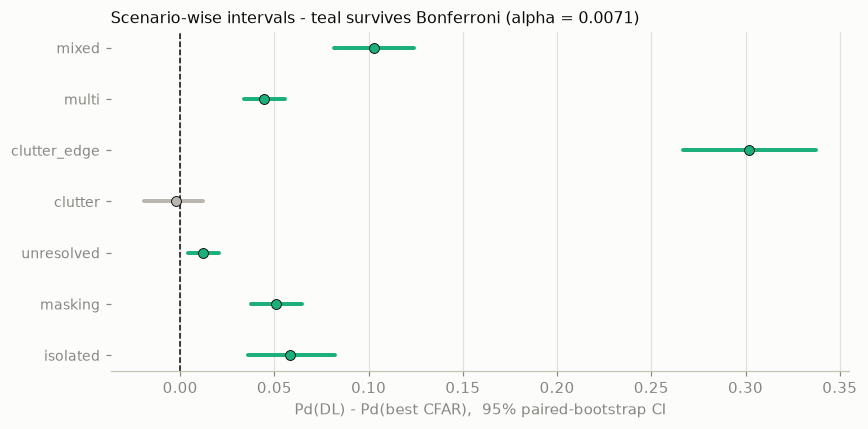

,diff,95% CI,"p (raw, as stored)",p (as reported),survives Bonferroni
condition,,,,,
isolated,0.0581,"[+0.036, +0.082]",0.000,< 0.001,True
masking,0.0511,"[+0.037, +0.065]",0.000,< 0.001,True
unresolved,0.0119,"[+0.004, +0.020]",0.001,0.001,True
clutter,-0.0023,"[-0.019, +0.012]",0.793,0.793,False
clutter_edge,0.3017,"[+0.267, +0.337]",0.000,< 0.001,True
multi,0.0446,"[+0.034, +0.056]",0.000,< 0.001,True
mixed,0.1031,"[+0.082, +0.124]",0.000,< 0.001,True


In [34]:
BOOT1 = pd.read_csv(DLR / "bootstrap_frozen_ep021_test_tol1.csv").set_index("condition")
BOOT1 = BOOT1.reindex([c for c in ORDER if c in BOOT1.index])
alpha_c = 0.05 / len(BOOT1)

fig, ax = plt.subplots(figsize=(8.0, 4.0))
y = np.arange(len(BOOT1))
ax.axvline(0, color=INK, linewidth=1.0, linestyle="--")
for i, (cond, r) in enumerate(BOOT1.iterrows()):
    sig = r.p_boot < alpha_c
    c = AQUA if sig else GREY
    ax.plot([r.ci_lo, r.ci_hi], [i, i], color=c, linewidth=2.6, solid_capstyle="round")
    ax.scatter(r["diff"], i, color=c, s=42, zorder=4, edgecolor=INK, linewidths=0.6)
ax.set_yticks(y); ax.set_yticklabels(BOOT1.index, fontsize=9)
ax.set_xlabel("Pd(DL) - Pd(best CFAR),  95% paired-bootstrap CI")
ax.set_title(f"Scenario-wise intervals - teal survives Bonferroni (alpha = {alpha_c:.4f})",
             loc="left", fontsize=10.5)
ax.grid(axis="x", linewidth=0.8); ax.set_axisbelow(True)
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

tab = pd.DataFrame({
    "diff": BOOT1["diff"],
    "95% CI": [f"[{a:+.3f}, {b:+.3f}]" for a, b in zip(BOOT1.ci_lo, BOOT1.ci_hi)],
    "p (raw, as stored)": BOOT1.p_boot,
    "p (as reported)": [fmt_p(p, N_BOOT) for p in BOOT1.p_boot],
    "survives Bonferroni": BOOT1.p_boot < alpha_c,
})
display(tab.round(4))

**In simple terms.** The p-value helps us judge whether the measured DL-versus-CFAR difference
is stable enough to be considered statistically detectable rather than just a result of which test
frames happened to be sampled. A small p-value gives stronger evidence of a difference, while a large
p-value means the data does not clearly separate the two methods. Because we perform this comparison
on seven different conditions, we use a stricter significance limit of $p < 0.0071$ instead of the
usual $p < 0.05$.

### 9.1 Never report `p = 0`

A stored bootstrap p-value of `0.0` does not mean that the true probability is literally zero. It
only means that none of the 2,000 bootstrap resamples produced a result on the opposite side of the
comparison. Because only a finite number of bootstrap samples were used, there is a limit to how
small a p-value can be measured. For this two-sided test with 2,000 resamples, the smallest useful
resolution is approximately $2/2000 = 0.001$. Therefore, a stored value of zero is reported as
$p < 0.001$ rather than $p = 0$ — which is what `fmt_p()` above prints.

In [35]:
print("resolution floor with", N_BOOT, "resamples:", f"{2 / N_BOOT:.4f}")
for p in [0.0, 0.0005, 0.001, 0.0071, 0.79]:
    print(f"  stored p = {p:<8} -> report as  p {fmt_p(p, N_BOOT)}")

resolution floor with 2000 resamples: 0.0010
  stored p = 0.0      -> report as  p < 0.001
  stored p = 0.0005   -> report as  p < 0.001
  stored p = 0.001    -> report as  p 0.001
  stored p = 0.0071   -> report as  p 0.007
  stored p = 0.79     -> report as  p 0.790


**In simple terms.** `p = 0` only means that the bootstrap did not observe an opposite result in
the 2,000 samples it tried. It does not mean that an opposite result is mathematically impossible. We
therefore report the result as $p < 0.001$, which reflects the resolution of the bootstrap
experiment.

### 9.2 Statistical significance is not practical significance

Statistical significance tells us whether a measured difference is consistently detectable in the
data, but it does not tell us whether that difference is large or important. The `unresolved`
condition is a good example. On the final test, DL reaches about 0.476 Pd while the best CFAR reaches
about 0.464, a difference of only 0.012, or 1.2 percentage points. The difference has $p = 0.001$, so
it passes the Bonferroni significance threshold, but the effect itself is very small. Both methods
remain close to the expected 0.5 ceiling of the unresolved scenario. The correct interpretation is
therefore that the difference is **statistically significant but practically negligible**, rather
than a meaningful DL advantage.

**Why the `unresolved` condition exists.** It is mainly a physics and evaluator sanity check. It
deliberately places two targets so close together that they fall inside one radar mainlobe and cannot
normally produce two separate resolvable peaks. There are still two labelled targets, but usually
only one physical return can be detected separately, so Pd naturally stays near 0.5. The purpose of
this condition is therefore not mainly to find a winner between DL and CFAR, but to check that
neither detector appears to overcome a physical resolution limit without a very strong reason.

**Why that sanity check matters — it has already caught a real bug.** Earlier in development, DL
produced about **0.547** Pd on the `unresolved` condition, which appeared to exceed the expected
physical ceiling. That suspicious result helped expose an NMS plateau bug: tied CNN output cells
could produce multiple nearby detections, giving one target several matching attempts. After the
plateau handling was fixed, the four methods returned to approximately **0.490** Pd on this
condition. The `unresolved` scenario therefore served exactly as intended — an apparently impossible
result triggered investigation rather than being interpreted as super-resolution. The plateau fix
itself is `_collapse_plateaus` (§1.2), and the evaluator check that now guards against it is in §10.

*(Those two figures come from the pre-re-specification benchmark, before the radar was re-specified
to the CARRADA geometry, so they are not directly comparable with the 0.464 / 0.476 above. The
ceiling argument is unchanged by the re-specification — it follows from two targets sharing one
mainlobe, not from the sensor.)*

In [36]:
u = BOOT1.loc["unresolved"] if "unresolved" in BOOT1.index else None
if u is not None:
    print(f"unresolved: best CFAR Pd {u.cfar_pd:.4f}   DL Pd {u.dl_pd:.4f}   "
          f"difference {u['diff']:+.4f} ({100 * u['diff']:+.2f} percentage points)")
    print(f"            95% CI [{u.ci_lo:+.4f}, {u.ci_hi:+.4f}], p {fmt_p(u.p_boot, N_BOOT)}, "
          f"Bonferroni alpha {alpha_c:.4f} -> passes: {bool(u.p_boot < alpha_c)}")
    print(f"            p sits at the bootstrap resolution floor ({2 / N_BOOT:.4f}): "
          f"{'yes' if abs(u.p_boot - 2 / N_BOOT) < 1e-9 else 'no'}")
    print(f"            {int(u.targets)} targets contributing, both arms near the ~0.5 "
          f"two-targets-in-one-mainlobe ceiling")
    print(f"            -> statistically significant, practically negligible")

unresolved: best CFAR Pd 0.4637   DL Pd 0.4756   difference +0.0119 (+1.19 percentage points)
            95% CI [+0.0042, +0.0205], p 0.001, Bonferroni alpha 0.0071 -> passes: True
            p sits at the bootstrap resolution floor (0.0010): yes
            800 targets contributing, both arms near the ~0.5 two-targets-in-one-mainlobe ceiling
            -> statistically significant, practically negligible


**In simple terms.** A small p-value tells us that a difference is consistently visible in the
data; it does not tell us that the difference is large or useful. We therefore interpret every result
using both the p-value and the size of the Pd difference, together with the radar physics. A large
and statistically significant difference can support a meaningful detector advantage, while a tiny
but statistically significant difference, such as `unresolved`, should not automatically be called a
win.

---

**§9 in one paragraph.** Effect size tells us how big the difference is. The bootstrap tells us how
stable it is to the finite test sample. The p-value tells us whether the difference is statistically
detectable. Bonferroni makes that significance test stricter because we repeat it across seven
conditions. Radar physics then tells us whether a statistically detectable difference is actually
meaningful.

---
## 10 · Does the evaluator behave correctly?

**The question:** every number above depends on one function. What has been checked?

The cells below are **targeted regression and sanity checks**, not a proof of correctness. Each one
constructs a small case whose answer is known in advance and confirms the evaluator returns it. They
run live against `src/eval/detection.py` and `src/cfar/detect.py`; there is no separate pytest suite
in this project, so these cells *are* the regression suite and run on every rebuild. Detailed
demonstrations of each case are in the appendix.

The evaluation code is responsible for turning detector outputs into every result reported in
this study, so several simple cases are tested where the correct answer is known in advance. These
checks verify that empty frames are handled correctly, one detection cannot match multiple targets,
detections outside the matching gate are not counted as true positives, guard and valid-mask cells
are handled correctly in the false-alarm calculation, localization errors are converted correctly,
and threshold and ROC behavior is consistent. If any of these checks fails, the notebook stops rather
than continuing with results that may be invalid. Passing the checks does not prove that the
evaluator contains no possible bugs, but it confirms the main behaviors and protects against
important failure modes encountered during development.

**In simple terms**, this section tests the ruler before using it to measure the detectors. If the
evaluator counted targets, false alarms or localization errors incorrectly, even perfectly working
CFAR and DL models would produce misleading results. Small examples with known answers therefore
provide a direct way to check that the scoring rules implemented in code behave the way the
experiment says they should.

In [37]:
checks = []


def check(name, cond, detail=""):
    checks.append(dict(check=name, result="PASS" if cond else "FAIL", detail=detail))


# empty truths / empty detections
e_nt = evaluate_frame(np.array([[3.0, 3.0]]), np.zeros((0, 2)), TOY_SHAPE, GATE)
e_nd = evaluate_frame(np.zeros((0, 2)), np.array([[3.0, 3.0]]), TOY_SHAPE, GATE)
e_both = evaluate_frame(np.zeros((0, 2)), np.zeros((0, 2)), TOY_SHAPE, GATE)
check("empty truths -> detection is an FP, no crash", (e_nt.tp, e_nt.fp, e_nt.fn) == (0, 1, 0),
      f"TP/FP/FN = {e_nt.tp}/{e_nt.fp}/{e_nt.fn}")
check("empty detections -> truth is an FN", (e_nd.tp, e_nd.fp, e_nd.fn) == (0, 0, 1),
      f"TP/FP/FN = {e_nd.tp}/{e_nd.fp}/{e_nd.fn}")
check("both empty -> all zero", (e_both.tp, e_both.fp, e_both.fn) == (0, 0, 0), "")

# duplicates on one truth
dup = evaluate_frame(np.array([[5.0, 5.0], [5.0, 5.0], [5.0, 6.0]]),
                     np.array([[5.0, 5.0]]), TOY_SHAPE, GATE)
check("duplicate detections -> exactly one TP", dup.tp == 1 and dup.fp == 0,
      f"3 detections on 1 truth -> TP={dup.tp}, FP={dup.fp}, {3 - dup.tp - dup.fp} forgiven")

# PLATEAU COLLAPSE, tested at the point it actually happens: all_peaks(), before matching.
# The duplicate test above covers how duplicates are COUNTED; this covers whether they are
# PRODUCED. Milestone 16's defect was here, not in the counting.
_flat_ok, _flat_detail = True, []
for _sz in (1, 3, 5):
    _m = np.zeros((30, 30))
    _m[10:10 + _sz, 10:10 + _sz] = 5.0                # one connected, perfectly flat plateau
    _n = len(all_peaks(_m, np.ones_like(_m, dtype=bool), nms_size=NMS))
    _flat_ok &= (_n == 1)
    _flat_detail.append(f"{_sz}x{_sz}->{_n}")
_two = np.zeros((40, 40))
_two[8:11, 8:11] = 5.0
_two[28:31, 28:31] = 7.0
_n_two = len(all_peaks(_two, np.ones_like(_two, dtype=bool), nms_size=NMS))
check("one flat score plateau -> exactly ONE candidate (all_peaks)",
      _flat_ok and _n_two == 2,
      f"plateau size->candidates: {', '.join(_flat_detail)}; two separated plateaus -> {_n_two}")

# one detection between two truths
btw = evaluate_frame(np.array([[5.0, 6.0]]), np.array([[5.0, 5.0], [5.0, 7.0]]), TOY_SHAPE, GATE)
check("one detection cannot claim two truths", btw.tp == 1 and btw.fn == 1,
      f"TP={btw.tp}, FN={btw.fn}")

# outside tolerance
out = evaluate_frame(np.array([[7.0, 7.0]]), np.array([[5.0, 5.0]]), TOY_SHAPE, GATE)
check("detection outside the gate -> FN + FP, not a large error",
      (out.tp, out.fp, out.fn) == (0, 1, 1) and not out.dr,
      f"TP/FP/FN = {out.tp}/{out.fp}/{out.fn}, errors recorded: {len(out.dr)}")

# border detection and valid-mask handling
bmask = np.zeros(TOY_SHAPE, dtype=bool); bmask[2:-2, 2:-2] = True
b_no = evaluate_frame(np.array([[9.0, 9.0]]), np.zeros((0, 2)), TOY_SHAPE, GATE)
b_yes = evaluate_frame(np.array([[9.0, 9.0]]), np.zeros((0, 2)), TOY_SHAPE, GATE,
                       valid_mask=bmask)
check("valid_mask shrinks the Pfa denominator",
      b_yes.cells_tested == int(bmask.sum()) < b_no.cells_tested,
      f"{b_yes.cells_tested} vs {b_no.cells_tested} cells")
check("guard cells are removed from the denominator",
      evaluate_frame(np.zeros((0, 2)), np.array([[5.0, 5.0]]), TOY_SHAPE, GATE).cells_tested
      == TOY_SHAPE[0] * TOY_SHAPE[1] - 9,
      "one truth removes its 3x3 gate = 9 cells")

# localization conversion
loc = evaluate_frame(np.array([[6.0, 4.0]]), np.array([[5.0, 5.0]]), TOY_SHAPE, GATE)
agg = aggregate([loc], range_res_m=RES_R, vel_res_mps=RES_V)
check("localization sign and unit conversion",
      loc.dr == [1] and loc.dv == [-1]
      and abs(agg["mean_abs_range_err_m"] - RES_R) < 1e-9
      and abs(agg["mean_abs_vel_err_mps"] - RES_V) < 1e-9,
      f"dr={loc.dr} dv={loc.dv} -> {agg['mean_abs_range_err_m']:.4f} m, "
      f"{agg['mean_abs_vel_err_mps']:.4f} m/s")

# threshold application
_pk = PEAKS["CA"][int(FM_VAL.frame.iloc[0])]
_hi = float(np.quantile(_pk[:, 2], 0.9))
check("threshold keeps exactly the peaks at or above it",
      len(_pk[_pk[:, 2] >= _hi]) == int((_pk[:, 2] >= _hi).sum()) < len(_pk),
      f"{int((_pk[:, 2] >= _hi).sum())} of {len(_pk)} peaks survive")

# ROC monotonicity
_viol = []
for (_c, _m), _g in ROC.groupby(["condition", "method"]):
    _g = _g.sort_values("threshold")
    if (_g.pd.diff().dropna() > 1e-12).any() or (_g.pfa_per_cell.diff().dropna() > 1e-12).any():
        _viol.append(f"{_c}/{_m}")
check("ROC is monotone on EVERY exported curve: raising the threshold cannot raise Pd or Pfa",
      not _viol,
      f"{ROC.groupby(['condition', 'method']).ngroups} curves "
      f"({ROC.condition.nunique()} conditions x {ROC.method.nunique()} methods), "
      f"{len(ROC)} swept points; violations: {_viol or 'none'}")

# gate monotonicity
check("for a FIXED set of detections, widening the gate cannot remove an existing TP",
      EV3.tp >= EV1.tp,
      f"same detections scored twice: TP {EV1.tp} (+/-1) -> {EV3.tp} (+/-3)")
check("widening the gate also widens the guard (they share one MatchConfig)",
      int(_guard_mask(TOY_TRUTHS, TOY_SHAPE, GATE3).sum())
      > int(_guard_mask(TOY_TRUTHS, TOY_SHAPE, GATE).sum()),
      f"{int(_guard_mask(TOY_TRUTHS, TOY_SHAPE, GATE).sum())} -> "
      f"{int(_guard_mask(TOY_TRUTHS, TOY_SHAPE, GATE3).sum())} guard cells")

CHECKS = pd.DataFrame(checks)
display(CHECKS.style.hide(axis="index"))
assert (CHECKS.result == "PASS").all(), "an evaluator check FAILED -- do not trust results above"
print(f"{len(CHECKS)} checks, all PASS")

check,result,detail
"empty truths -> detection is an FP, no crash",PASS,TP/FP/FN = 0/1/0
empty detections -> truth is an FN,PASS,TP/FP/FN = 0/0/1
both empty -> all zero,PASS,
duplicate detections -> exactly one TP,PASS,"3 detections on 1 truth -> TP=1, FP=0, 2 forgiven"
one flat score plateau -> exactly ONE candidate (all_peaks),PASS,"plateau size->candidates: 1x1->1, 3x3->1, 5x5->1; two separated plateaus -> 2"
one detection cannot claim two truths,PASS,"TP=1, FN=1"
"detection outside the gate -> FN + FP, not a large error",PASS,"TP/FP/FN = 0/1/1, errors recorded: 0"
valid_mask shrinks the Pfa denominator,PASS,196 vs 324 cells
guard cells are removed from the denominator,PASS,one truth removes its 3x3 gate = 9 cells
localization sign and unit conversion,PASS,"dr=[1] dv=[-1] -> 0.1952 m, 0.4201 m/s"


14 checks, all PASS


**Several of these cover failure modes that actually occurred.**

**The plateau check guards Milestone 16's defect directly.** `all_peaks` used
`score == maximum_filter(score)`, which marks *every* cell of a flat region as a local maximum. A
CFAR ratio is continuous and rarely ties; a network's output has genuinely flat regions, so one
target could emit several detections — and because unmatched detections inside a truth's guard region
are set aside (§4), the duplicates cost nothing while inflating Pd. The check above tests the stage
where that happened: whether `all_peaks` *produces* one candidate per plateau.

**The duplicate-detection check is a different test, and the difference is worth being precise
about.** It feeds ready-made duplicate detections to `evaluate_frame` and confirms they are *counted*
correctly — one TP, the rest set aside. It would have passed throughout the Milestone 16 period,
because the counting was never the broken part. The two checks cover the production and the counting
halves of one failure mode, and only together do they cover it.

**How the defect was actually caught is the more useful lesson**, and it was neither check: DL scored
0.547 on `unresolved`, above the ~0.5 two-targets-in-one-mainlobe ceiling. A physics sanity check
found what a unit test had no reason to look for (§9.2). That is the argument for keeping
impossible-by-construction conditions in a benchmark.

**The ROC-monotonicity and threshold checks** cover the three interpolation bugs found in Milestone
20b, one of which recovered a threshold 4× too high on `isolated`.

---
## 11 · What this protocol shows, and what it does not

**Shows.** Everything below concerns the pipeline **after** each detector has produced its score map;
the score maps themselves are what the two methods are being compared on, so they are the one stage
that is deliberately *not* shared.

* **Fair post-processing** — the same `all_peaks()` implementation and the same NMS radius, for both
  arms (§1).
* **A common evaluation region** — the same border-excluded mask and the same Pfa denominator (§2).
* **A common matching rule** — optimal one-to-one assignment, ±1 bin, pre-registered (§3).
* **A common false-alarm burden** — matched *measured* post-NMS Pfa, with the achieved rate printed
  beside every operating point as a protocol check (§5, §7.1). On the reported split that check came
  back within 2% of target for every method on every condition
  (`results/dl/measured_pfa_frozen_ep021_test_tol1.csv`).
* **Paired frame-sampling uncertainty** — a paired bootstrap over frames, quantifying how much the
  measured difference depends on which frames happened to be generated (§8). Separately, a
  **robustness check re-selects the best CFAR variant inside every bootstrap replicate** and confirms
  that winner-selection uncertainty does not materially change the intervals (§8.1). The reported
  intervals remain the fixed-winner ones.
* **Robustness to the matching tolerance** — the pre-registered ±1 headline result is accompanied by
  a ±3 robustness analysis (§3).
* **Targeted evaluator checks** — the regression and sanity checks in §10 run on every rebuild. They
  confirm the main behaviours; they do not prove the absence of every possible bug.

**Does not show.**

* **CFAR-like behaviour by the network.** The threshold is chosen per method and per condition from
  labelled data. Nothing here tests whether a *single fixed* threshold holds Pfa constant as clutter
  changes, which is the property CFAR is named for (§7.2).
* **Real-world generalization.** Every frame comes from one simulator. `bench2_test` shares a
  generator with `bench2_val` — different frames, different seed, no shared content, but not a
  different world. This establishes **sampling generalization only**, not survival under a different
  clutter model, a different sensor, or measured data.
* **That a significant difference matters.** `unresolved` is the standing example: statistically
  significant, one percentage point, at a physics ceiling (§9.2).
* **That ±1 is the only reasonable localization definition.** The per-axis error is bounded by the
  gate width, and a different gate would give a different — also defensible — number. The ±1 gate is
  the pre-registered headline definition, while ±3 is reported as a robustness check (§3.1, §6).
* **That the guard convention is neutral.** Setting aside unmatched near-target detections is
  generous to any detector that clusters detections. §4.1 measures how much is actually being
  forgiven, which is the evidence that it is not doing real work here — but it remains a convention,
  not a law.

### 11.1 In summary

**What the protocol establishes.** This evaluation protocol makes the CFAR-versus-DL comparison as
consistent as possible after each detector produces its score map. Both methods use the same peak
extraction and NMS rules, are evaluated over the same valid region of the Range–Doppler map, use the
same matching and false-alarm definitions, and are compared at approximately the same measured
post-NMS Pfa. The main result uses the pre-registered ±1 matching gate, while ±3 is used as a
robustness check. Frame-sampling uncertainty is measured using a paired bootstrap, and an additional
robustness analysis checks whether uncertainty about which CFAR variant is best changes the
conclusions. Together, these controls support a fair comparison of detector performance under the
simulated test conditions.

**What it does not establish.** These controls do not make the experiment more general than the data
it uses. The DL threshold is chosen separately for each condition using labelled data, so the
experiment does not show that one fixed DL threshold can maintain a constant false-alarm rate across
changing environments. All training, validation and test frames also come from the same simulator
family, so the test measures performance on new simulated samples rather than real-world
generalization. Statistical significance must still be interpreted together with effect size and
radar physics, localization results depend on the chosen matching gate, and the truth-guard treatment
of nearby unmatched detections remains an evaluation convention rather than a universal rule.

**In simple terms:** the protocol makes the CFAR-versus-DL comparison fair within this simulated
experiment, but it does not prove that DL will behave like CFAR or perform the same way on a real
radar.

---
# Appendix — evaluation edge cases and implementation checks

Low-level detail, kept out of the main flow.

### A.1 The two detection paths agree, at the thresholds that are actually used

`extract_detections(ratio, valid, alpha)` thresholds *inside* peak extraction; the ROC path calls
`all_peaks()` before the operating cut and filters afterwards. Every reported number uses the second.

They are **not** identical by construction: `_collapse_plateaus` keeps one representative per
connected region of the peak mask, and that region can differ between the two paths when a plateau
straddles the threshold. So the equivalence §1.1a relies on is checked here — at each CFAR variant's
own matched operating point, rather than at round numbers.

The `detections` column matters: a threshold so high that both paths return nothing agrees
trivially, and would prove nothing.

In [38]:
cfar_ops = (OPP[OPP.method != "DL"][["condition", "method", "threshold"]]
            .sort_values("threshold").reset_index(drop=True))
n_check = 15
frames = sorted((ROOT / "data" / "bench2_val" / "frames").iterdir())[:n_check]
cached = [cfar_ratio_map(np.load(fd / "rd_map_mag.npy") ** 2, CFAR_CFG)[:2] for fd in frames]

rows = []
for _, r in cfar_ops.iterrows():
    a = float(r.threshold)
    agree, n_det = 0, 0
    for ratio, valid in cached:
        one = {(int(rr), int(vv)) for rr, vv, _ in extract_detections(ratio, valid, a, NMS)}
        pk = all_peaks(ratio, valid, NMS)
        two = {(int(q[0]), int(q[1])) for q in pk[pk[:, 2] > a]}
        agree += (one == two)
        n_det += len(two)
    rows.append(dict(condition=r.condition, method=r.method, alpha=round(a, 3),
                     detections=n_det, frames_identical=agree))

A1 = pd.DataFrame(rows)
display(A1.style.hide(axis="index"))
nontrivial = A1[A1.detections > 0]
print(f"{len(A1)} operating points spanning alpha {A1.alpha.min():.2f}-{A1.alpha.max():.2f}, "
      f"{n_check} frames each.")
print(f"{len(nontrivial)} of them return at least one detection "
      f"({nontrivial.detections.min()}-{nontrivial.detections.max()} over the {n_check} frames), "
      f"so the agreement is not vacuous.")
assert (A1.frames_identical == n_check).all(), "the two detection paths disagree somewhere"
assert len(nontrivial) >= len(A1) - 2, "too many operating points return nothing to test"
print("Identical detections on every frame at every operating point tested.")

condition,method,alpha,detections,frames_identical
masking,OS,7.206000,246,15
isolated,OS,7.260000,242,15
isolated,GO,9.142000,113,15
masking,GO,9.202000,112,15
masking,CA,9.968000,83,15
isolated,CA,10.061000,80,15
isolated,SO,12.161000,48,15
masking,SO,12.281000,48,15
clutter_edge,GO,15.974000,29,15
clutter_edge,OS,19.542000,19,15


12 operating points spanning alpha 7.21-308.74, 15 frames each.
12 of them return at least one detection (2-246 over the 15 frames), so the agreement is not vacuous.
Identical detections on every frame at every operating point tested.


### A.2 The `score > 0` floor in `all_peaks`, and why it binds on nothing

`all_peaks` keeps cells with `score > 0`. For CFAR the ratio is a positive power ratio, so this
excludes nothing. For the network, scored on **logits**, it means only cells with sigmoid > 0.5 ever
become candidate peaks — a real floor on how far the DL ROC can be swept toward high Pfa. It matters
only if an operating point approaches it.

In [39]:
dl_thr = OPP[OPP.method == "DL"][["condition", "threshold"]]
display(dl_thr.round(4).style.hide(axis="index"))
print(f"lowest DL operating threshold across these conditions: {dl_thr.threshold.min():.3f} logits")
print(f"the floor is 0.0 logits (sigmoid 0.5) -> margin "
      f"{dl_thr.threshold.min():.3f} logits above it")
print("So the floor truncates only the high-Pfa tail of the DL ROC, far from where anything")
print("is scored. It is an implementation detail to be aware of, not a defect in a reported number.")

condition,threshold
isolated,1.399900
masking,1.392000
clutter_edge,1.702800


lowest DL operating threshold across these conditions: 1.392 logits
the floor is 0.0 logits (sigmoid 0.5) -> margin 1.392 logits above it
So the floor truncates only the high-Pfa tail of the DL ROC, far from where anything
is scored. It is an implementation detail to be aware of, not a defect in a reported number.


### A.3 Plateau collapse, demonstrated

In [40]:
flat = np.zeros((14, 14))
flat[6:9, 6:9] = 5.0                      # a perfectly flat 3x3 blob
valid_flat = np.ones_like(flat, dtype=bool)
peak_flat = flat == maximum_filter(flat, size=2 * NMS + 1, mode="nearest")
raw = int((valid_flat & peak_flat & (flat > 0)).sum())
collapsed = len(all_peaks(flat, valid_flat, nms_size=NMS))
print(f"cells flagged as local maxima on a flat 3x3 blob : {raw}")
print(f"detections after _collapse_plateaus              : {collapsed}")
print("Without the collapse, one blob would emit 9 detections; 8 of them would land inside the")
print("truth's guard region and be forgiven, inflating detection counts at no false-alarm cost.")

cells flagged as local maxima on a flat 3x3 blob : 9
detections after _collapse_plateaus              : 1
Without the collapse, one blob would emit 9 detections; 8 of them would land inside the
truth's guard region and be forgiven, inflating detection counts at no false-alarm cost.


### A.4 Gate geometry

The gate is a **square**, not a disc: `|dr| <= tol AND |dv| <= tol`. A detection at (1, 1) is
1.41 bins away in Euclidean distance and is accepted; one at (2, 0) is 2.0 bins away and is not.
Distance is used only to *rank* eligible pairs inside the assignment, never to decide eligibility.

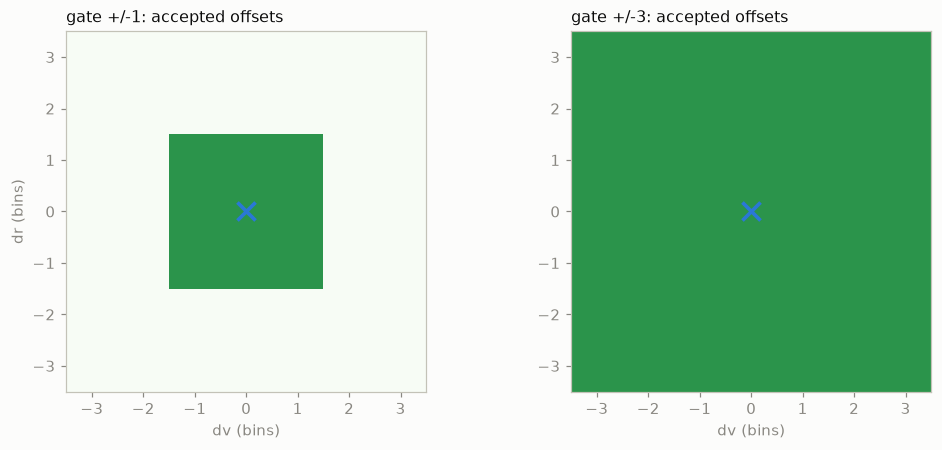

+/-1 gate accepts 9 offsets, Euclidean distance up to 1.414 bins
+/-3 gate accepts 49 offsets (5.4x the area)


In [41]:
grid = []
for dr in range(-3, 4):
    for dv in range(-3, 4):
        e1 = evaluate_frame(np.array([[9.0 + dr, 9.0 + dv]]), np.array([[9.0, 9.0]]),
                            TOY_SHAPE, GATE)
        e3 = evaluate_frame(np.array([[9.0 + dr, 9.0 + dv]]), np.array([[9.0, 9.0]]),
                            TOY_SHAPE, GATE3)
        grid.append(dict(dr=dr, dv=dv, euclid=float(np.hypot(dr, dv)),
                         tp_gate1=e1.tp, tp_gate3=e3.tp))
G = pd.DataFrame(grid)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.2))
for ax, col, name in zip(axes, ["tp_gate1", "tp_gate3"], ["gate +/-1", "gate +/-3"]):
    M = G.pivot(index="dr", columns="dv", values=col).to_numpy()
    ax.imshow(M, origin="lower", cmap="Greens", vmin=0, vmax=1.4,
              extent=[-3.5, 3.5, -3.5, 3.5])
    ax.scatter(0, 0, marker="x", s=140, color=BLUE, linewidths=2.4)
    ax.set_title(f"{name}: accepted offsets", loc="left", fontsize=10.5)
    ax.set_xlabel("dv (bins)"); ax.grid(False)
axes[0].set_ylabel("dr (bins)")
plt.tight_layout(); plt.show()

edge = G[(G.tp_gate1 == 1)].euclid
print(f"+/-1 gate accepts {int(G.tp_gate1.sum())} offsets, Euclidean distance up to "
      f"{edge.max():.3f} bins")
print(f"+/-3 gate accepts {int(G.tp_gate3.sum())} offsets "
      f"({G.tp_gate3.sum() / G.tp_gate1.sum():.1f}x the area)")

### A.5 Where each rule lives in the source

| rule | file |
|---|---|
| peak extraction, NMS, plateau collapse | `src/cfar/detect.py` — `all_peaks`, `_collapse_plateaus` |
| valid mask | `src/dl/infer.py` — `cfar_valid_mask` |
| matching, guard region, TP/FP/FN | `src/eval/detection.py` — `evaluate_frame`, `_guard_mask` |
| metric aggregation | `src/eval/detection.py` — `aggregate` |
| threshold grid and ROC sweep | `src/eval/detection.py` — `roc_thresholds`, `roc_curve` |
| matched-Pfa operating point | `src/dl/stratified_eval.py` — `_at_measured_pfa` |
| paired bootstrap, Bonferroni | `scripts/bootstrap_comparison.py` |
| best-CFAR re-selection | `scripts/bootstrap_best_cfar_reselect.py` |
| common-subset localization | `scripts/localization_common_subset.py` |
| ROC export for this notebook | `scripts/roc_curve_export.py` |

---
*Rebuild with `python scripts/build_evaluation_metrics_nb.py`. Every number is computed at run time
from the project's own evaluation code, from cached detections, or from result CSVs; nothing is
pasted.*